# E-commerce Sales & Customer Analytics: Exploratory Analysis

## Overview
Exploratory analysis of an e-commerce dataset (about 138k orders) to understand which customer, channel and order characteristics affect **sales, profit, returns and cancellations**.

## Data
Four tables, loaded from a Google Drive folder:

| Table | Content |
|---|---|
| `ecommerce_sales_customer_analytics_150k` | One row per order (sales, profit, status, channel, customer fields) |
| `order_items` | One row per item in an order |
| `product_catalog` | One row per product |
| `customer_master` | One row per customer |

Derived tables used below: `order_df` (order level) and `item_df` (item level).

## Questions
1. Is the data clean and are the tables consistent with each other?
2. How are orders, sales and profit distributed (status, channel, age, gender, customer segment)?
3. Which groups differ in profit per order, margin, returns or cancellations?

## Contents
1. Setup and data loading
2. Dataset overview
3. Data integrity checks and analysis tables
4. Missing values and duplicates
5. Order-level analysis (completed orders)
6. Scanning columns for differences
7. EDA toolkit demo
8. Descriptive statistics
9. Additional column checks (currency, delivery, rating, tax, discount)
10. Conclusion: order-level analysis
11. Item-level analysis
12. Next steps

> Note: customer names and postal codes are hidden in the outputs.

## 1. Setup and data loading

In [1]:
import pandas as pd
import numpy as np


import seaborn as sns
import matplotlib.pyplot as plt


import os, glob

In [2]:
"""eda_toolkit.py - reusable EDA helpers: overview, univariate, bivariate, multivariate.

Usage (Colab):
    from eda_toolkit import EDA
    eda = EDA(order_df, name="order_df")
    done = eda.subset(lambda d: d["order_status"] == "Completed", name="completed")
    done.overview()
    done.univariate("net_sales")
"""


class EDA:
    def __init__(self, df, name="data", cat_max=15):
        self.df = df
        self.name = name
        self.cat_max = cat_max          # numeric columns with <= cat_max distinct values are treated as categorical

    # ------------------------------------------------------------------
    # Helpers
    # ------------------------------------------------------------------
    def kind(self, col):
        """Return 'date', 'numeric' (continuous) or 'categorical' for a column."""
        s = self.df[col]
        if pd.api.types.is_datetime64_any_dtype(s):
            return "date"
        if pd.api.types.is_numeric_dtype(s) and s.nunique() > self.cat_max:
            return "numeric"
        return "categorical"

    def subset(self, condition, name=None):
        """New EDA object on the rows where condition(df) is True (e.g. completed orders only)."""
        d = self.df[condition(self.df)].copy()
        return EDA(d, name or f"{self.name}_subset", self.cat_max)

    @staticmethod
    def _monthly(s):
        """Monthly resampler that works on old and new pandas versions."""
        try:
            return s.resample("ME")
        except ValueError:
            return s.resample("M")

    # ------------------------------------------------------------------
    # Overview of all columns
    # ------------------------------------------------------------------
    def overview(self):
        """One table with the kind, dtype, nulls, unique count and an example for every column."""
        d = self.df
        out = pd.DataFrame({
            "kind": [self.kind(c) for c in d.columns],
            "dtype": d.dtypes.astype(str).values,
            "non_null": d.notna().sum().values,
            "null_%": (d.isna().mean() * 100).round(1).values,
            "unique": d.nunique().values,
            "example": d.iloc[0].values,
        }, index=d.columns)
        is_float = np.array([pd.api.types.is_float_dtype(d[c]) for c in d.columns])
        out.loc[(out["unique"].values == len(d)) & ~is_float, "kind"] = "id-like"
        print(f"{self.name}: {d.shape[0]:,} rows x {d.shape[1]} columns")
        return out

    # ------------------------------------------------------------------
    # Univariate
    # ------------------------------------------------------------------
    def numeric_profile(self, col):
        """Descriptive numbers for one numeric column in a single table."""
        s = self.df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        outlier_share = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
        out = pd.Series({
            "count": len(s), "nulls": self.df[col].isna().sum(),
            "mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
            "std": s.std(), "cv": s.std() / s.mean() if s.mean() != 0 else np.nan,
            "min": s.min(), "p5": s.quantile(0.05), "q1": q1, "q3": q3,
            "p95": s.quantile(0.95), "max": s.max(), "iqr": iqr,
            "skew": s.skew(), "excess_kurtosis": s.kurt(),
            "outlier_share_%": outlier_share,
        })
        return out.round(2)

    def univariate(self, col, top_n=10, log=False):
        """Summary and plot for one column, chosen by its type."""
        s = self.df[col]
        print("=" * 60)
        print(f"[{self.name}] {col} | dtype: {s.dtype} | unique: {s.nunique()} | "
              f"nulls: {s.isna().sum()} ({s.isna().mean():.1%})")
        print("Examples:", s.dropna().unique()[:5])

        if s.nunique() == len(s) and not pd.api.types.is_float_dtype(s):
            print("-> Looks like an ID column, skipping.")
            return

        k = self.kind(col)
        if k == "date":
            print("Range:", s.min(), "to", s.max())
            s.dt.to_period("M").value_counts().sort_index().plot(figsize=(10, 3))
            plt.title(f"{col}: records per month"); plt.show()

        elif k == "numeric":
            print(self.numeric_profile(col).to_string())
            fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
            sns.histplot(s.dropna(), bins=40, ax=ax[0], log_scale=log)
            ax[0].set_title(f"{col}: distribution")
            sns.boxplot(x=s.dropna(), ax=ax[1], log_scale=log)
            ax[1].set_title(f"{col}: boxplot")
            plt.tight_layout(); plt.show()

        else:
            vc = s.value_counts(dropna=False)
            if s.nunique() > 50:
                print("-> High-cardinality column, showing only the top", top_n)
            print((vc / len(s) * 100).round(1).head(top_n))
            top = vc.head(top_n)
            plt.figure(figsize=(8, 3.5))
            plt.bar(top.index.astype(str), top.values)
            plt.xticks(rotation=30, ha="right")
            plt.title(f"{col}: counts (top {top_n})"); plt.ylabel("count"); plt.tight_layout(); plt.show()

    def outlier_report(self, col, k=1.5, top=10, show_cols=None):
        """IQR-rule outliers: how many, how much of the total they carry, and the biggest rows.
        Nothing is deleted; the returned boolean Series lets you flag them."""
        s = self.df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - k * iqr, q3 + k * iqr
        flag = (s < lo) | (s > hi)
        print(f"{col}: fences = [{lo:.1f}, {hi:.1f}] | flagged = {flag.mean():.1%} ({flag.sum():,} rows)")
        if (s >= 0).all():
            print(f"Share of the column total carried by flagged rows: {s[flag].sum() / s.sum():.1%}")
        cols = show_cols or [col]
        print(self.df.loc[s.nlargest(top).index, cols])
        return flag.reindex(self.df.index, fill_value=False)

    # ------------------------------------------------------------------
    # Bivariate
    # ------------------------------------------------------------------
    def bivariate(self, x, y, top_n=10, sample=20000, log=False):
        """Two columns together; the plot depends on their types.
        log=True puts numeric axes on a log scale (helps with skewed money columns)."""
        df = self.df
        kx, ky = self.kind(x), self.kind(y)
        if kx == "numeric" and ky == "categorical":          # keep the categorical column on x
            x, y, kx, ky = y, x, ky, kx
        print(f"[{self.name}] {x} ({kx})  vs  {y} ({ky})")

        if kx == "numeric" and ky == "numeric":
            full = df[[x, y]].dropna()
            d = full.sample(min(sample, len(full)), random_state=1)
            fig, ax = plt.subplots(1, 2, figsize=(12, 4))
            ax[0].scatter(d[x], d[y], s=5, alpha=0.3); ax[0].set_title("scatter (sample)")
            ax[1].hexbin(d[x], d[y], gridsize=40, cmap="Blues", mincnt=1); ax[1].set_title("density (hexbin)")
            for a in ax:
                a.set_xlabel(x); a.set_ylabel(y)
                if log:
                    a.set_xscale("log"); a.set_yscale("log")
            plt.tight_layout(); plt.show()
            print("Spearman:", round(full[x].corr(full[y], method="spearman"), 3),
                  "| Pearson:", round(full[x].corr(full[y]), 3), "| n =", len(full))

        elif kx == "categorical" and ky == "numeric":
            top = df[x].value_counts().head(top_n).index
            d = df[df[x].isin(top)]
            order = d.groupby(x, observed=True)[y].median().sort_values().index
            fig, ax = plt.subplots(figsize=(10, 4))
            sns.boxplot(data=d, x=x, y=y, order=order, showfliers=False, ax=ax)
            ax.set_title(f"{y} by {x} (outliers hidden, top {top_n} groups)")
            if log:
                ax.set_yscale("log")
            plt.xticks(rotation=30); plt.show()
            print(d.groupby(x, observed=True)[y].agg(["count", "mean", "median", "std"]).round(2).loc[order[::-1]])

        elif kx == "categorical" and ky == "categorical":
            tx = df[x].value_counts().head(top_n).index
            ty = df[y].value_counts().head(top_n).index
            d = df[df[x].isin(tx) & df[y].isin(ty)]
            row_pct = pd.crosstab(d[x], d[y], normalize="index") * 100      # P(y | x) in percent
            fig, ax = plt.subplots(1, 2, figsize=(13, 4))
            sns.heatmap(row_pct, annot=True, fmt=".1f", cmap="Blues", ax=ax[0])
            ax[0].set_title(f"% of {y} within each {x}")
            row_pct.plot(kind="bar", stacked=True, ax=ax[1]); ax[1].set_title("stacked share")
            ax[1].legend(title=y, bbox_to_anchor=(1, 1))
            plt.tight_layout(); plt.show()
            print(pd.crosstab(d[x], d[y], margins=True))

        elif "date" in (kx, ky):
            dcol, vcol = (x, y) if kx == "date" else (y, x)
            if self.kind(vcol) != "numeric":
                print("Date vs categorical is not supported here; use a numeric column."); return
            m = self._monthly(df.set_index(dcol)[vcol]).agg(["sum", "mean", "count"])
            m[["sum"]].plot(figsize=(10, 3), title=f"{vcol}: monthly total")
            plt.show()
            print(m.tail())

    def group_table(self, by, value, profit=None, top_n=15):
        """Count, share, mean and median of `value` per group.
        If `profit` is given, adds the weighted margin = sum(profit) / sum(value) * 100."""
        g = self.df.groupby(by, observed=True)
        t = pd.DataFrame({
            "count": g.size(),
            "total": g[value].sum(),
            "mean": g[value].mean(),
            "median": g[value].median(),
        })
        t["share_%"] = t["total"] / t["total"].sum() * 100
        if profit:
            t["weighted_margin_%"] = g[profit].sum() / g[value].sum() * 100
        return t.sort_values("total", ascending=False).head(top_n).round(2)

    # ------------------------------------------------------------------
    # Multivariate
    # ------------------------------------------------------------------
    def corr_heatmap(self, cols, method="spearman"):
        """Correlation matrix of several numeric columns."""
        c = self.df[cols].corr(method=method)
        mask = np.triu(np.ones_like(c, dtype=bool))
        plt.figure(figsize=(8, 6))
        sns.heatmap(c, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
        plt.title(f"{self.name}: {method} correlation"); plt.show()
        return c

    def pair_plot(self, cols, hue=None, sample=3000):
        """Pairwise scatter plots on a random sample (full data would be too slow)."""
        d = self.df[cols + ([hue] if hue else [])].dropna()
        d = d.sample(min(sample, len(d)), random_state=1)
        sns.pairplot(d, hue=hue, corner=True, plot_kws={"s": 8, "alpha": 0.4})
        plt.show()

    def multi_plot(self, x, y, hue, top_n=6, sample=15000, log_y=False):
        """x and y with a third categorical column as colour (numeric x) or grouped boxes (categorical x)."""
        top = self.df[hue].value_counts().head(top_n).index
        d = self.df[self.df[hue].isin(top)]
        kx, ky = self.kind(x), self.kind(y)
        if kx == "numeric" and ky == "numeric":
            d = d.sample(min(sample, len(d)), random_state=1)
            plt.figure(figsize=(9, 5))
            sns.scatterplot(data=d, x=x, y=y, hue=hue, s=10, alpha=0.4)
        elif kx == "categorical" and ky == "numeric":
            plt.figure(figsize=(11, 5))
            sns.boxplot(data=d, x=x, y=y, hue=hue, showfliers=False)
            plt.xticks(rotation=30)
        else:
            print("Use numeric x numeric, or categorical (x) with numeric (y)."); return
        if log_y:
            plt.yscale("log")
        plt.title(f"{y} by {x}, split by {hue}"); plt.legend(bbox_to_anchor=(1, 1)); plt.show()

    def pivot_heatmap(self, row, col, value=None, agg="median", ratio=None, min_count=30):
        """Heatmap of an aggregate across two categorical columns.
        ratio=("profit", "net_sales") gives the weighted margin sum(profit) / sum(net_sales) * 100.
        Cells with fewer than min_count rows are blanked so tiny groups do not mislead."""
        df = self.df
        cnt = df.groupby([row, col], observed=True).size().unstack()
        if ratio:
            g = df.groupby([row, col], observed=True)
            table = (g[ratio[0]].sum() / g[ratio[1]].sum() * 100).unstack()
            title = f"{ratio[0]} / {ratio[1]} (%)"
        elif value:
            table = df.pivot_table(index=row, columns=col, values=value, aggfunc=agg, observed=True)
            title = f"{agg} of {value}"
        else:
            table, title = cnt, "number of rows"
        table = table.where(cnt >= min_count)
        plt.figure(figsize=(9, 5))
        sns.heatmap(table, annot=True, fmt=".1f", cmap="viridis")
        plt.title(f"{title}: {row} x {col}"); plt.show()
        return table

In [3]:
def load_all(folder, show=True):
    readers = {
        ".csv": pd.read_csv,
        ".tsv": lambda p: pd.read_csv(p, sep="\t"),
        ".xlsx": pd.read_excel,
        ".xls": pd.read_excel,
        ".json": pd.read_json,
        ".parquet": pd.read_parquet,
    }
    data = {}
    for path in sorted(glob.glob(os.path.join(folder, "**", "*"), recursive=True)):
        ext = os.path.splitext(path)[1].lower()
        if ext not in readers:
            continue
        name = os.path.splitext(os.path.basename(path))[0]
        try:
            data[name] = readers[ext](path)
            if show:
                print(f"✅ {name:30s} shape={data[name].shape}")
        except Exception as e:
            try:
                data[name] = pd.read_csv(path, encoding="latin-1")
                if show:
                    print(f"✅ {name:30s} shape={data[name].shape} (latin-1)")
            except Exception:
                print(f"{name}: {e}")
    return data

In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
data = load_all('/content/drive/MyDrive/Data')

✅ customer_master                shape=(25000, 11)
✅ dataset_statistics             shape=(1, 11)
✅ ecommerce_sales_customer_analytics_150k shape=(138116, 46)
✅ order_items                    shape=(397569, 12)
✅ product_catalog                shape=(1175, 9)


In [6]:
import re

def to_variable(data, suffix ="", namespace = None):

  ns = namespace if namespace is not None else globals() # putt the all the data which is in the dict they give the name of the data

  created = []

  for name , df in data.items():
    var = re.sub(r"\W", "_",name).strip("_").lower()+suffix
    if var and var[0].isdigit():
      var = "_df"+var
    ns[var] = df
    created.append(var)
  print("variables are created:", created)

to_variable(data)

variables are created: ['customer_master', 'dataset_statistics', 'ecommerce_sales_customer_analytics_150k', 'order_items', 'product_catalog']


## 2. Dataset overview

In [7]:
# check the datasets one by one (personal columns hidden)
customer_master.drop(columns=["customer_name", "customer_postal_code"], errors="ignore").sample(5)

,customer_id,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_acquisition_cost
18030,CUST-018031,22,Female,Premium,Anthonyhaven,Texas,USA,South,25.97
11185,CUST-011186,19,Non-Binary,Consumer,Saundersbury,Michigan,USA,Central,19.14
14720,CUST-014721,20,Female,Consumer,Thomasburgh,Georgia,USA,South,44.58
12628,CUST-012629,21,Male,VIP,Wilsonmouth,California,USA,West,51.50
11803,CUST-011804,23,Male,Premium,Port Victoriaburgh,England,UK,North,54.66


In [8]:
dataset_statistics

,Total Transactions,Total Columns,Total Customers,Total Products Used,Date Range,Total Revenue,Total Profit,Average Order Value,Average Rating,Return Rate,Cancellation Rate
0,138116,46,24911,138116,2021-01-01 to 2025-12-31,"$177,134,263.74","$76,146,395.76","$1,282.50",3.68,6.85%,6.08%


In [9]:
ecommerce_sales_customer_analytics_150k.drop(columns=["customer_name", "customer_postal_code"], errors="ignore").sample(5)

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_age,gender,customer_segment,customer_type,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
134101,ORD-473993,2023-05-18,17:16:41,Returned,Marketplace,CUST-005197,65,Male,Consumer,Loyal,...,0.00,29.04,12.21,186.43,49.12,125.10,67.10,7673.37,True,6
63037,ORD-727428,2023-08-29,22:09:57,Completed,Mobile App,CUST-022203,40,Female,Premium,Loyal,...,167.82,72.68,45.16,844.62,409.86,389.60,46.13,11628.05,True,11
1805,ORD-279041,2024-12-15,02:35:24,Completed,Mobile App,CUST-008676,48,Female,Premium,Loyal,...,938.88,184.98,18.41,2845.95,1855.52,972.02,34.15,7238.15,True,5
23030,ORD-465522,2023-10-20,13:06:51,Completed,Website,CUST-013959,54,Male,Consumer,Loyal,...,181.25,423.42,8.84,2549.36,1574.10,966.42,37.91,11773.50,True,7
16587,ORD-158286,2023-06-05,20:42:22,Completed,Mobile App,CUST-007682,19,Male,Premium,Loyal,...,230.81,306.29,16.81,2679.19,1382.59,1279.79,47.77,12754.19,True,7


In [10]:
order_items.sample(5)

,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
174788,ORD-521599,PROD-000150,3,627.36,0.207277,390.11,1882.08,104.44,5.77,1602.18,929.88,666.53
156761,ORD-549486,PROD-000634,3,474.60,0.301141,428.76,1423.80,69.65,15.24,1079.93,806.25,258.44
13600,ORD-436346,PROD-001046,1,63.59,0.162829,10.35,63.59,3.73,11.98,68.95,27.71,29.26
263021,ORD-529073,PROD-000144,2,181.95,0.000000,0.00,363.90,25.47,3.73,393.10,158.56,230.81
269991,ORD-884227,PROD-001112,1,66.54,0.000000,0.00,66.54,4.66,6.27,77.47,34.77,36.43


In [11]:
product_catalog.sample(5)

,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
228,PROD-000229,MAC Enhanced tangible model Skincare,Beauty & Personal Care,Skincare,MAC,Direct Import,140.11,61.54,3.9
919,PROD-000920,Fisher-Price Phased empowering projection Furn...,Baby & Kids,Furniture,Fisher-Price,Global Trade,313.20,160.46,2.6
712,PROD-000713,Castrol Organic reciprocal forecast Cleaning,Automotive,Cleaning,Castrol,Amazon Supply,66.06,40.92,2.9
1051,PROD-001052,PepsiCo Virtual bifurcated alliance Meat,Grocery,Meat,PepsiCo,Euro Logistics,45.62,16.45,4.1
671,PROD-000672,Bosch Profit-focused coherent approach Car Ele...,Automotive,Car Electronics,Bosch,Pacific Trade,100.76,56.40,3.5


In [12]:
ecommerce_sales_customer_analytics_150k.shape

(138116, 46)

In [13]:
ecommerce_sales_customer_analytics_150k.columns

Index(['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_id', 'customer_name', 'customer_age', 'gender',
       'customer_segment', 'customer_type', 'customer_city', 'customer_state',
       'customer_country', 'region', 'customer_postal_code', 'payment_method',
       'payment_status', 'currency', 'shipping_method', 'warehouse',
       'delivery_days', 'estimated_delivery_days', 'delivery_status',
       'return_status', 'return_reason', 'customer_rating', 'review_sentiment',
       'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code',
       'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity',
       'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost',
       'net_sales', 'product_cost', 'profit', 'profit_margin_percentage',
       'customer_lifetime_value', 'is_repeat_customer',
       'customer_order_count'],
      dtype='object')

In [14]:
product_catalog.columns

Index(['product_id', 'product_name', 'product_category', 'product_subcategory',
       'brand', 'supplier', 'unit_price', 'product_cost', 'product_rating'],
      dtype='object')

In [15]:
order_items.columns

Index(['order_id', 'product_id', 'quantity', 'unit_price',
       'discount_percentage', 'discount_amount', 'gross_sales', 'tax_amount',
       'shipping_cost', 'net_sales', 'product_cost', 'profit'],
      dtype='object')

## 3. Data integrity checks and analysis tables
Keys, join coverage, building `order_df` and `item_df`, and whether the tables agree with each other.

### 3.1 Keys and join coverage

In [16]:
sales = ecommerce_sales_customer_analytics_150k.copy()
items, prod, cust = order_items, product_catalog, customer_master

print("sales order_id unique:", sales["order_id"].is_unique)
print("cust customer_id unique:", cust["customer_id"].is_unique)
print("prod product_id unique:", prod["product_id"].is_unique)

print("items order_id sales me mile:", items["order_id"].isin(sales["order_id"]).mean())
print("items product_id catalog me mile:", items["product_id"].isin(prod["product_id"]).mean())
print("sales customer_id master me mile:", sales["customer_id"].isin(cust["customer_id"]).mean())

print(cust.columns.tolist())
print(sales["return_status"].value_counts(dropna=False))
print(sales["order_status"].value_counts(dropna=False))

sales order_id unique: True
cust customer_id unique: True
prod product_id unique: True
items order_id sales me mile: 1.0
items product_id catalog me mile: 1.0
sales customer_id master me mile: 1.0
['customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'customer_acquisition_cost']
return_status
NaN         128654
Returned      9462
Name: count, dtype: int64
order_status
Completed    113559
Returned       9462
Cancelled      8398
Pending        6697
Name: count, dtype: int64


### 3.2 Building the analysis tables

In [17]:
order_df = sales.merge(customer_master[["customer_id", "customer_acquisition_cost"]],
                        on="customer_id", how="left", validate="m:1")


order_df["order_date"] = pd.to_datetime(order_df["order_date"])
order_df["returned"] = order_df["return_status"].notna().astype(int)
order_df["has_coupon"] = order_df["coupon_code"].notna().astype(int)
order_df["has_campaign"] = order_df["campaign_name"].notna().astype(int)

In [18]:
order_df.shape

(138116, 50)

**New columns:** tax removed from net sales and profit, and discount as % of gross.

In [80]:
# New columns: tax removed from net sales and profit, and discount as % of gross
order_df["net_sales_ex_tax"] = order_df["net_sales"] - order_df["tax_amount"]
order_df["profit_ex_tax"] = order_df["profit"] - order_df["tax_amount"]
order_df["discount_pct"] = order_df["discount_amount"] / order_df["gross_sales"] * 100

In [83]:
# profit - profit_ex_tax should equal tax_amount in every row
print((order_df["profit"] - order_df["profit_ex_tax"] - order_df["tax_amount"]).abs().max())
order_df[["profit", "profit_ex_tax", "tax_amount"]].head()

4.547473508864641e-13


,profit,profit_ex_tax,tax_amount
0,345.04,283.97,61.07
1,-22.47,-343.30,320.83
2,197.57,167.78,29.79
3,247.83,213.44,34.39
4,1530.36,1109.01,421.35


In [19]:
item_df = (
    order_items
    .merge(product_catalog, on="product_id", how="left", validate="m:1", suffixes=("", "_catalog"))
    .merge(order_df[["order_id", "order_date", "order_status", "returned",
                     "customer_id", "region", "marketing_channel"]],
           on="order_id", how="left", validate="m:1")
)

print(item_df.shape)

(397569, 26)


In [ ]:
item_df.drop(columns="customer_id", errors="ignore").head()

### 3.3 Consistency between the tables

In [21]:
# ---- Check 1: do sales and customer_master agree on shared columns? ----
cols = ["customer_age", "gender", "customer_segment", "region"]
m = sales[["customer_id"] + cols].merge(
    customer_master[["customer_id"] + cols], on="customer_id", suffixes=("", "_m"))
for c in cols:
    print(c, "mismatch %:", round((m[c] != m[c + "_m"]).mean() * 100, 2))

# ---- Check 2: do order_items totals match sales totals per order? ----
agg = order_items.groupby("order_id")[["quantity", "net_sales", "profit"]].sum()
cmp = sales.set_index("order_id")[["quantity", "net_sales", "profit"]].join(
    agg, rsuffix="_items", how="inner")
print("orders compared:", len(cmp))
for c in ["quantity", "net_sales", "profit"]:
    d = (cmp[c] - cmp[c + "_items"]).abs()
    print(c, "max diff:", round(d.max(), 2), "| rows with diff > 0.01:", (d > 0.01).sum())

# ---- Check 3: summary stats and odd values ----
print(order_df[["gross_sales", "discount_amount", "net_sales", "profit",
                "profit_margin_percentage", "quantity", "delivery_days"]].describe().T)
print("negative profit orders:", (order_df["profit"] < 0).sum())
print("negative net_sales:", (order_df["net_sales"] < 0).sum())

# Is net_sales equal to gross_sales minus discount_amount?
print("net = gross - discount, max diff:",
      (order_df["net_sales"] - (order_df["gross_sales"] - order_df["discount_amount"])).abs().max())

customer_age mismatch %: 0.0
gender mismatch %: 0.0
customer_segment mismatch %: 0.0
region mismatch %: 0.0
orders compared: 138116
quantity max diff: 31 | rows with diff > 0.01: 11226
net_sales max diff: 11139.31 | rows with diff > 0.01: 11226
profit max diff: 5181.37 | rows with diff > 0.01: 11226
                             count         mean          std      min  \
gross_sales               138116.0  1375.384176  1291.009554     6.31   
discount_amount           138116.0   237.621614   378.779459     0.00   
net_sales                 138116.0  1282.503575  1169.274669     5.80   
profit                    138116.0   551.322046   516.300936 -1281.59   
profit_margin_percentage  138116.0    45.065997    13.120357   -59.55   
quantity                  138116.0     5.615244     3.371289     1.00   
delivery_days             113559.0     4.557772     2.810012     0.00   

                               25%      50%        75%       max  
gross_sales               458.9200  995.730  18

In [22]:
# ---- A. Where do items-vs-sales mismatches come from? ----
cmp["net_diff"] = cmp["net_sales_items"] - cmp["net_sales"]    # items total minus sales total
cmp["bad"] = cmp["net_diff"].abs() > 0.01
cmp = cmp.join(sales.set_index("order_id")["order_status"])
cmp = cmp.join(order_items.groupby("order_id").size().rename("n_items"))

print("Mismatch rate by order status:")
print(cmp.groupby("order_status")["bad"].agg(["mean", "sum"]))
print("\nMismatch rate by number of items in the order:")
print(cmp.groupby("n_items")["bad"].mean())
print("\nDifference size (mismatched orders only):")
print(cmp.loc[cmp["bad"], "net_diff"].describe())
print("Share where items total > sales total:", (cmp.loc[cmp["bad"], "net_diff"] > 0).mean())
print(cmp[cmp["bad"]].head())

# ---- B. What does net_sales actually contain? ----
tmp = order_df.copy()
tmp["gap"] = tmp["net_sales"] - (tmp["gross_sales"] - tmp["discount_amount"])
candidates = {
    "tax": tmp["tax_amount"],
    "shipping": tmp["shipping_cost"],
    "tax + shipping": tmp["tax_amount"] + tmp["shipping_cost"],
}
for name, extra in candidates.items():
    print(f"gap vs {name}: max abs diff =", round((tmp["gap"] - extra).abs().max(), 2))

# ---- C. How is profit_margin_percentage defined? ----
print("margin = profit / net_sales * 100, max diff:",
      (tmp["profit"] / tmp["net_sales"] * 100 - tmp["profit_margin_percentage"]).abs().max())

# ---- D. Are negative-profit orders the heavily discounted ones? ----
tmp["discount_pct"] = tmp["discount_amount"] / tmp["gross_sales"] * 100
tmp["neg_profit"] = tmp["profit"] < 0
print(tmp.groupby("neg_profit")["discount_pct"].describe())


Mismatch rate by order status:
                  mean   sum
order_status                
Cancelled     0.078352   658
Completed     0.081605  9267
Pending       0.078692   527
Returned      0.081801   774

Mismatch rate by number of items in the order:
n_items
1     0.000000
2     0.010755
3     0.038425
4     0.099023
5     0.152095
6     1.000000
7     1.000000
8     1.000000
9     1.000000
10    1.000000
11    1.000000
12    1.000000
13    1.000000
14    1.000000
17    1.000000
18    1.000000
Name: bad, dtype: float64

Difference size (mismatched orders only):
count    11226.000000
mean      1359.755349
std       1234.364874
min         13.810000
25%        483.912500
50%       1015.995000
75%       1853.960000
max      11139.310000
Name: net_diff, dtype: float64
Share where items total > sales total: 1.0
            quantity  net_sales   profit  quantity_items  net_sales_items  \
order_id                                                                    
ORD-163733         7     4

In [ ]:
# remove personal / unused columns (after item_df and the consistency checks, which still need customer_id)
order_df = order_df.drop(columns=['order_time', 'customer_id', 'customer_name'], errors='ignore')

## 4. Missing values and duplicates

In [23]:
#chek the null values of the data and info as well

order_df.isnull().sum()

,0
order_id,0
order_date,0
order_time,0
order_status,0
sales_channel,0
customer_id,0
customer_name,0
customer_age,0
gender,0
customer_segment,0


In [24]:
order_df.duplicated().sum()

np.int64(0)

In [25]:
order_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   order_id                   138116 non-null  object        
 1   order_date                 138116 non-null  datetime64[ns]
 2   order_time                 138116 non-null  object        
 3   order_status               138116 non-null  object        
 4   sales_channel              138116 non-null  object        
 5   customer_id                138116 non-null  object        
 6   customer_name              138116 non-null  object        
 7   customer_age               138116 non-null  int64         
 8   gender                     138116 non-null  object        
 9   customer_segment           138116 non-null  object        
 10  customer_type              138116 non-null  object        
 11  customer_city              138116 non-null  object  

in this data there are few columns which has the null vlaues and first we check what we can do this null vlaues and how we can deal with that

##/ so we check that we can drop the column or we can fill that null values


## 5. Order-level analysis (completed orders)
`order_df` is the base table; most tables below use only `Completed` orders.

### 5.1 Order status

In [26]:
with pd.option_context("display.max_columns", None):
    display(order_df.drop(columns=["customer_name", "customer_postal_code"], errors="ignore").head())

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count,customer_acquisition_cost,returned,has_coupon,has_campaign
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,Digital Wallet,Paid,USD,Standard,WH-003,3.0,3.0,On Time,NaN,NaN,3.5,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11,73.06,0,0,1
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,Debit Card,Pending,EUR,Economy,WH-005,10.0,10.0,On Time,NaN,NaN,3.6,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11,67.27,0,0,1
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,Cash on Delivery,Paid,USD,Express,WH-015,3.0,3.0,On Time,NaN,NaN,4.3,Positive,Good product. Works as expected.,YouTube,NaN,NaN,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6,52.02,0,0,0
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,65,Male,Consumer,Loyal,Wigginsstad,North Carolina,USA,South,Debit Card,Paid,USD,Express,WH-010,2.0,2.0,On Time,NaN,NaN,3.5,Positive,Satisfied with the purchase.,Email Marketing,NaN,NaN,54,10,2,544.62,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7,65.91,0,0,0
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,34,Female,Consumer,Loyal,New Michaelton,Gujarat,India,West,Digital Wallet,Paid,INR,Standard,WH-013,6.0,5.0,Delayed,NaN,NaN,3.0,Neutral,Mixed feelings about this purchase.,Direct,NaN,NaN,278,147,6,2474.52,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8,66.26,0,0,0


In [27]:
#order_status
counts = order_df['order_status'].value_counts()
print(counts,'\n')
print((counts / counts.sum() * 100).round(2))

order_status
Completed    113559
Returned       9462
Cancelled      8398
Pending        6697
Name: count, dtype: int64 

order_status
Completed    82.22
Returned      6.85
Cancelled     6.08
Pending       4.85
Name: count, dtype: float64


### 5.2 Net sales

In [28]:
# this function is reusable we can use this for different differenct data:

def explore_column(df, col, top_n=10):
    """Print a quick summary of one column and plot it according to its type."""
    s = df[col]
    print("=" * 60)
    print(f"Column: {col} | dtype: {s.dtype} | unique: {s.nunique()} | nulls: {s.isna().sum()} ({s.isna().mean():.1%})")
    print("Examples:", s.dropna().unique()[:5])

    # ID-like column: every value is unique, nothing useful to plot
    if s.nunique() == len(s):
        print("-> Looks like an ID column, skipping.")
        return

    # Date column
    if pd.api.types.is_datetime64_any_dtype(s):
        print("Range:", s.min(), "to", s.max())
        s.dt.to_period("M").value_counts().sort_index().plot(figsize=(10, 3))
        plt.title(f"{col}: records per month"); plt.show()
        return

    # Numeric with many distinct values: continuous
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 15:
        print(s.describe().round(2))
        print("skew:", round(s.skew(), 2), "| median:", round(s.median(), 2))
        fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
        sns.histplot(s.dropna(), bins=40, ax=ax[0]); ax[0].set_title(f"{col}: distribution")
        sns.boxplot(x=s.dropna(), ax=ax[1]); ax[1].set_title(f"{col}: boxplot")
        plt.tight_layout(); plt.show()
        return

    # Few distinct values (numeric or text): treat as categorical
    vc = s.value_counts(dropna=False)
    if s.nunique() > 50:
        print("-> High-cardinality column, showing only the top", top_n)
    print((vc / len(s) * 100).round(1).head(top_n))
    vc.head(top_n).plot(kind="bar", figsize=(8, 3.5))
    plt.title(f"{col}: counts (top {top_n})"); plt.ylabel("count"); plt.show()

Column: net_sales | dtype: float64 | unique: 112204 | nulls: 0 (0.0%)
Examples: [ 945.4  2018.41  468.35  546.52 2785.27]
count    138116.00
mean       1282.50
std        1169.27
min           5.80
25%         448.20
50%         950.76
75%        1744.58
max       16218.00
Name: net_sales, dtype: float64
skew: 1.9 | median: 950.76


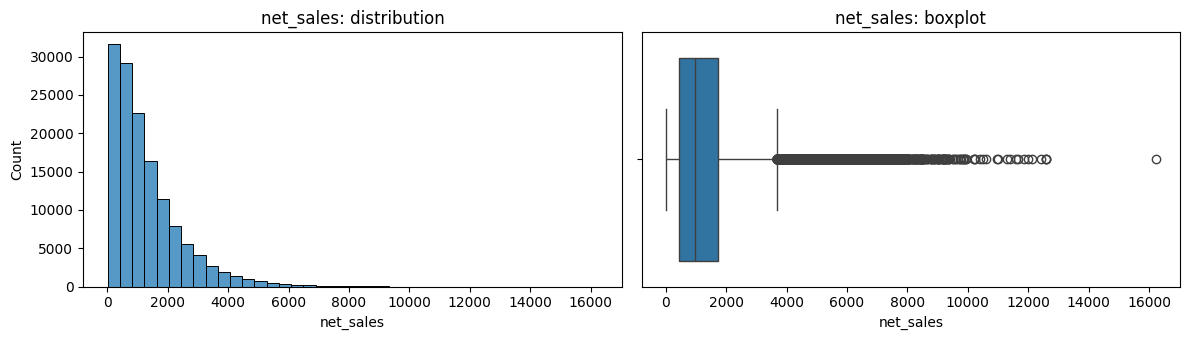

In [29]:
explore_column(order_df,'net_sales')

Column: net_sales | dtype: float64 | unique: 95344 | nulls: 0 (0.0%)
Examples: [ 945.4  2018.41  468.35  546.52 2785.27]
count    113559.00
mean       1269.79
std        1152.81
min           5.80
25%         443.22
50%         942.85
75%        1732.82
max       16218.00
Name: net_sales, dtype: float64
skew: 1.87 | median: 942.85


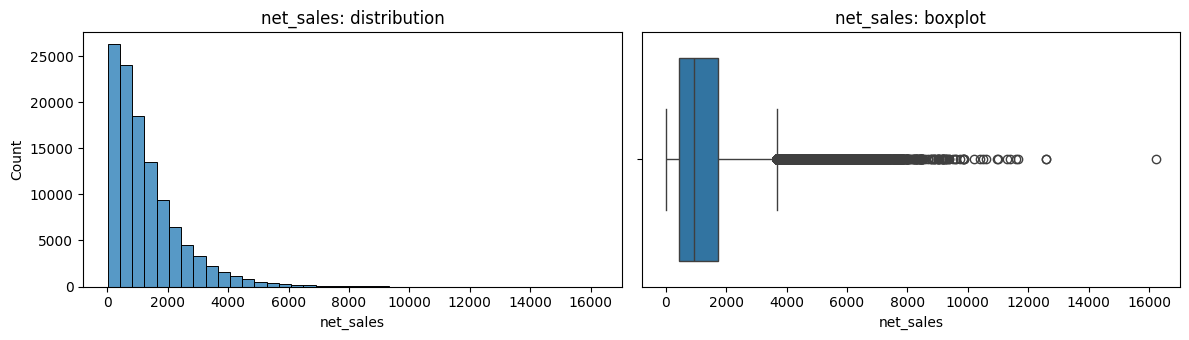

In [30]:
# we take the sepration on the basisi of the order_status
completed_order_df = order_df[order_df['order_status']=='Completed']
explore_column(completed_order_df,"net_sales")


as i observ that in this completed_order_df that the net_sales coulumns is we can see the the clear skweness of the net sales and also we can se the there is few order which is big and may be generate the good profit for that we can do some more observatoin realated to

Upper fence: 3667.2 | flagged share: 4.6 %
Revenue share of flagged orders: 17.2 %
          order_id  quantity  gross_sales  discount_amount  net_sales   profit
63317   ORD-296476        18     16051.19           936.34   16218.00  6209.49
26516   ORD-705120        14     12398.16           682.48   12604.07  4726.31
67605   ORD-179530        13     12725.10          1000.41   12578.45  5353.66
136990  ORD-362901        13     10586.49           882.70   11674.67  5103.25
116566  ORD-669275        13     10253.79           612.02   11585.22  5986.41
64097   ORD-575151        12     11180.36           547.98   11410.86  4403.90
16578   ORD-802711        14     11557.59          1062.08   11293.34  5303.10
22060   ORD-739328        14     11406.28          1179.16   10992.26  4170.43
92543   ORD-446087        14      9982.87           877.09   10962.82  5115.50
78886   ORD-129077        17     10288.18          1492.56   10594.31  4372.55
          count   median       max
n_items      

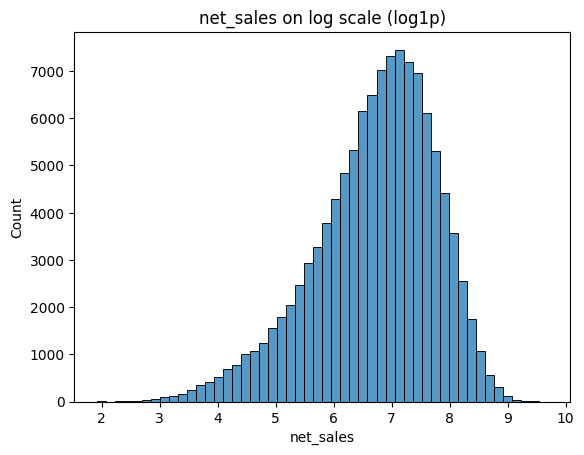

In [31]:
x = completed_order_df["net_sales"]

# 1. Share flagged by the IQR rule and the revenue they carry
q1, q3 = x.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
flag = x > upper_fence
print("Upper fence:", round(upper_fence, 1), "| flagged share:", round(flag.mean() * 100, 1), "%")
print("Revenue share of flagged orders:", round(x[flag].sum() / x.sum() * 100, 1), "%")

# 2. The ten biggest orders
print(completed_order_df.nlargest(10, "net_sales")[
    ["order_id", "quantity", "gross_sales", "discount_amount", "net_sales", "profit"]])

# 3. Are big orders multi-item orders?
n_items = order_items.groupby('order_id').size().rename("n_items")
tmp = completed_order_df.join(n_items, on="order_id")
print(tmp.groupby(pd.cut(tmp["n_items"], [0, 1, 3, 5, 100]), observed=True)["net_sales"]
         .agg(["count", "median", "max"]))

# 4. Log-scale view of the same column
sns.histplot(np.log1p(x), bins=50)
plt.title("net_sales on log scale (log1p)")
plt.show()



net_sales: observations (Completed orders, n = 113,559)

Continuous column with no missing values. Values range from 5.80 to 16,218.
The distribution is right-skewed (skew = 1.87). The mean (1,269.79) sits above the median (942.85) because a small number of large orders pull it up.
By the IQR rule, 4.6% of orders are flagged as outliers (above 3,667), and these orders account for 17.2% of total revenue.
The ten largest orders contain 12 to 18 units each, have discounts of roughly 5-10% of gross sales, and all have positive profit. They look like genuine large baskets, not data errors.
On a log scale (log1p), the distribution becomes much more symmetric, with a peak around 7 (about 1,100), though a slightly longer left tail remains.
Excluding Cancelled and Pending orders changes the mean by about 1% and the median by about 0.8%, so the shape stays the same.
Decision: outliers are retained because they are plausible and carry a large share of revenue. They are flagged, and the median and percentiles are reported alongside the mean.

### 5.3 Sales channel

Column: sales_channel | dtype: object | unique: 4 | nulls: 0 (0.0%)
Examples: ['Mobile App' 'Website' 'Social Media' 'Marketplace']
sales_channel
Mobile App      40.1
Website         34.9
Marketplace     15.0
Social Media    10.0
Name: count, dtype: float64


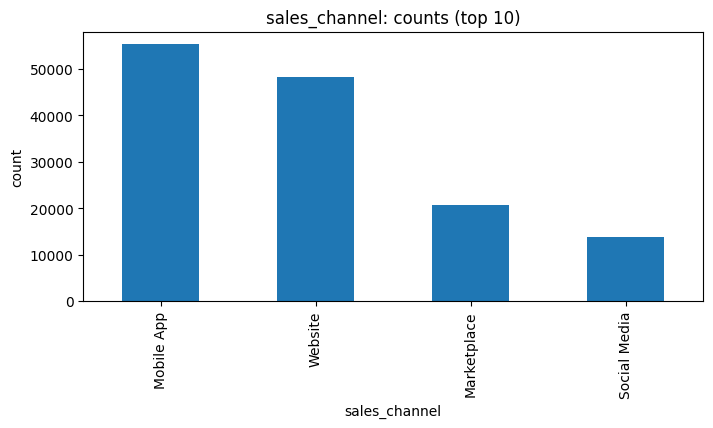

In [32]:
explore_column(order_df,
               'sales_channel')

Column: sales_channel | dtype: object | unique: 4 | nulls: 0 (0.0%)
Examples: ['Mobile App' 'Website' 'Social Media' 'Marketplace']
sales_channel
Mobile App      40.1
Website         34.9
Marketplace     15.0
Social Media    10.1
Name: count, dtype: float64


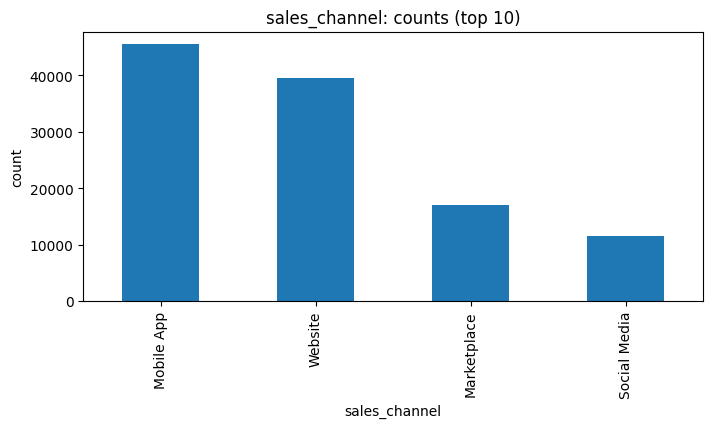

In [33]:
# also plot the completd_order plot for the sales_channel so we can comparie it
explore_column(completed_order_df,'sales_channel')

               orders   net_sales      profit  order_share_%  sales_share_%  \
sales_channel                                                                 
Mobile App      45505  57617393.1  23877395.0           40.1           40.0   
Website         39606  50345188.2  20887959.1           34.9           34.9   
Marketplace     16987  21775779.7   8983667.0           15.0           15.1   
Social Media    11461  14457477.6   6009448.0           10.1           10.0   

               profit_share_%  profit_per_order  weighted_margin_%  
sales_channel                                                       
Mobile App               40.0             524.7               41.4  
Website                  35.0             527.4               41.5  
Marketplace              15.0             528.9               41.3  
Social Media             10.1             524.3               41.6  
Check, shares add up to 100: 100.0


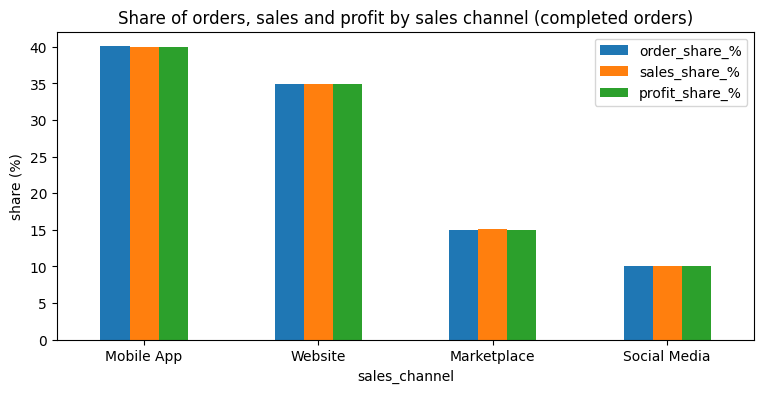

In [34]:
#Profit share by channel

profit_chanel =  completed_order_df
group_on_chanel =  profit_chanel.groupby('sales_channel')

tabel = pd.DataFrame({
    'orders':group_on_chanel.size(),
    "net_sales":group_on_chanel['net_sales'].sum(),
    'profit':group_on_chanel['profit'].sum()
})

tabel["order_share_%"] = tabel["orders"] / tabel["orders"].sum() * 100
tabel["sales_share_%"] = tabel["net_sales"] / tabel["net_sales"].sum() * 100
tabel["profit_share_%"] = tabel["profit"] / tabel["profit"].sum() * 100
tabel["profit_per_order"] = tabel["profit"] / tabel["orders"]
tabel["weighted_margin_%"] = tabel["profit"] / tabel["net_sales"] * 100


print(tabel.sort_values("profit", ascending=False).round(1))
print("Check, shares add up to 100:", tabel["profit_share_%"].sum().round(2))

share = tabel[["order_share_%", "sales_share_%", "profit_share_%"]].sort_values("profit_share_%", ascending=False)
ax = share.plot(kind="bar", figsize=(9, 4))
ax.set_ylabel("share (%)")
ax.set_title("Share of orders, sales and profit by sales channel (completed orders)")
plt.xticks(rotation=0)
plt.show()

Mobile App accounts for 40.1% of orders, Website 34.9%, Marketplace 15.0% and Social Media 10.1%.
Each channel’s share of sales and profit is almost identical to its share of orders (differences of 0.1 percentage points or less).
Profit per order is between 524 and 529 for all channels, and the weighted margin is between 41.3% and 41.6%.
Interpretation: the channels differ in volume but not in order value or profitability in this data.
Open question: is this flat pattern also true for region, customer segment, payment method and category? The consistency of the numbers may indicate synthetic data.
Limitation: order-level totals understate orders with 6+ items.

### 5.4 Customer age

Column: customer_age | dtype: int64 | unique: 57 | nulls: 0 (0.0%)
Examples: [55 26 69 65 34]
count    138116.00
mean         45.86
std          16.47
min          18.00
25%          32.00
50%          46.00
75%          60.00
max          74.00
Name: customer_age, dtype: float64
skew: 0.01 | median: 46.0


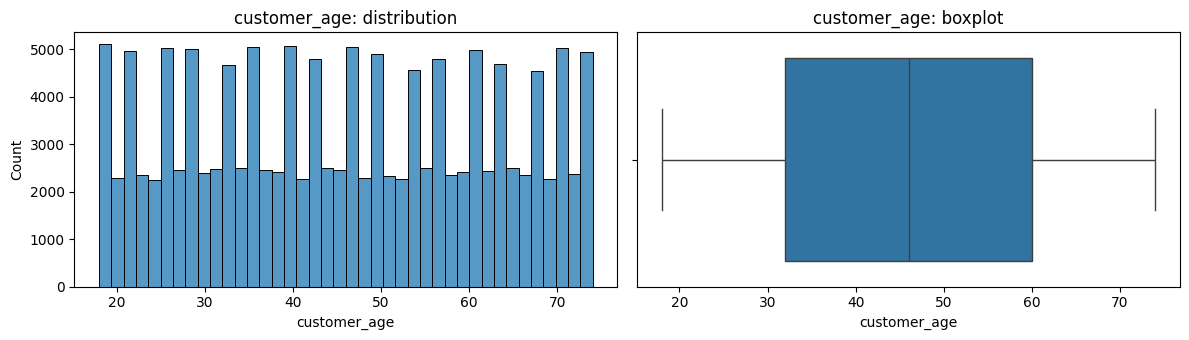

In [35]:
explore_column(order_df,'customer_age')

Age graph is shows that alsomost uniform like there is nothing special we can say that every age group play the same roll in this

<Axes: xlabel='customer_age', ylabel='Count'>

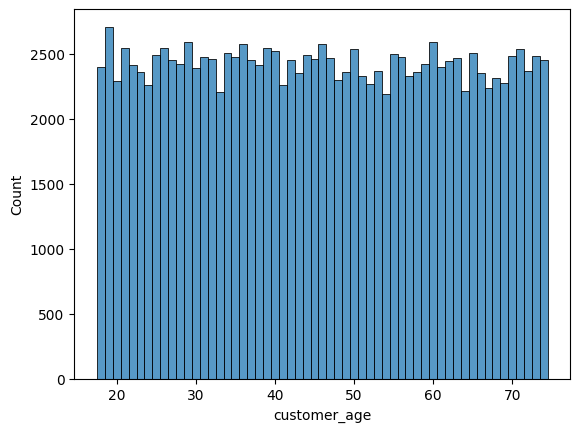

In [36]:
sns.histplot(order_df["customer_age"], discrete=True)

In [37]:
def share_table(df, by, value="net_sales", profit="profit"):
    """Order, sales and profit share, profit per order and weighted margin for each group."""
    g = df.groupby(by, observed=True)
    t = pd.DataFrame({
        "orders": g.size(),
        "sales": g[value].sum(),
        "profit": g[profit].sum(),
    })
    t["order_share_%"] = t["orders"] / t["orders"].sum() * 100
    t["profit_share_%"] = t["profit"] / t["profit"].sum() * 100
    t["profit_per_order"] = t["profit"] / t["orders"]
    t["weighted_margin_%"] = t["profit"] / t["sales"] * 100      # sum(profit) / sum(sales), not an average of margins
    return t.sort_values("profit", ascending=False).round(1)

# Completed orders only, split into age bands
d = completed_order_df.copy()
d["age_band"] = pd.cut(d["customer_age"], [17, 24, 34, 44, 54, 64, 74],
                       labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65-74"])

print(share_table(d, "age_band"))

          orders       sales      profit  order_share_%  profit_share_%  \
age_band                                                                  
35-44      20113  25755259.3  10649080.0           17.7            17.8   
25-34      20205  25591929.8  10531678.7           17.8            17.6   
55-64      19901  25219477.6  10485135.5           17.5            17.5   
65-74      19704  25077542.1  10402285.9           17.4            17.4   
45-54      19653  24788043.0  10295688.7           17.3            17.2   
18-24      13983  17763586.8   7394600.2           12.3            12.4   

          profit_per_order  weighted_margin_%  
age_band                                       
35-44                529.5               41.3  
25-34                521.2               41.2  
55-64                526.9               41.6  
65-74                527.9               41.5  
45-54                523.9               41.5  
18-24                528.8               41.6  


Age group vs profit (Completed orders, n = 113,559; table: order_df)

Orders were split into six age bands. Bands of 10 ages hold 17.3% to 17.8% of orders each; 18-24 (7 ages) holds 12.3%, as expected from its width.
Profit per order ranges from 521.2 to 529.5 across bands (about 1.6% spread), and the weighted margin from 41.2% to 41.6%.
Each band’s share of profit is within 0.2 percentage points of its share of orders.
Interpretation: in this dataset, age does not appear to affect order value or profitability.
Open question: is age related to returns, discount use or product category?
Limitation: this compares averages only, and customer age is almost uniform between 18 and 74, which is unusual for real customers, so the result may not carry over to real markets.

### 5.5 Gender

Column: gender | dtype: object | unique: 3 | nulls: 0 (0.0%)
Examples: ['Male' 'Female' 'Non-Binary']
gender
Female        48.1
Male          48.0
Non-Binary     3.9
Name: count, dtype: float64


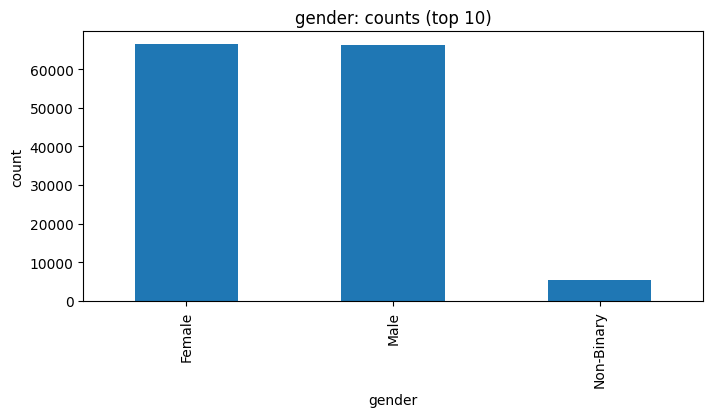

In [38]:
explore_column(order_df,"gender")

            orders   net_sales      profit  order_share_%  sales_share_%  \
gender                                                                     
Female       54660  69474743.6  28776267.9           48.1           48.2   
Male         54514  69110521.4  28644379.2           48.0           47.9   
Non-Binary    4385   5610573.5   2337821.9            3.9            3.9   

            profit_share_%  profit_per_order  weighted_margin_%  
gender                                                           
Female                48.2             526.5               41.4  
Male                  47.9             525.4               41.4  
Non-Binary             3.9             533.1               41.7  
Check, shares add up to 100: 100.0


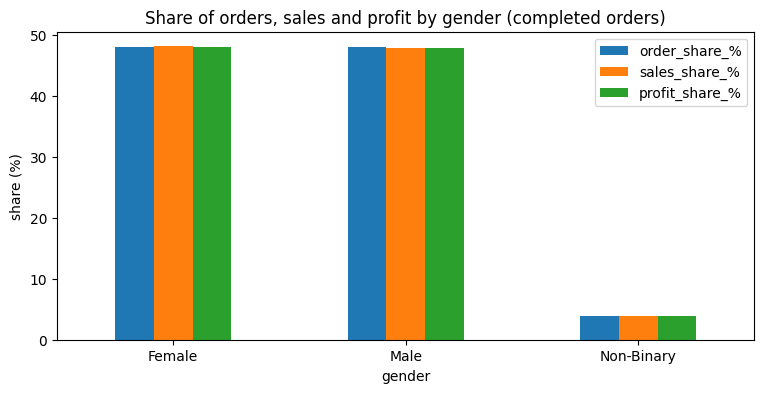

In [39]:
# gender wise profit and sales
gender_wise_completed_order = completed_order_df.groupby("gender")
gender_wise_completed_order

tabel_ = pd.DataFrame({
    'orders':gender_wise_completed_order.size(),
    "net_sales":gender_wise_completed_order['net_sales'].sum(),
    'profit':gender_wise_completed_order['profit'].sum()
})

tabel_["order_share_%"] = tabel_["orders"] / tabel_["orders"].sum() * 100
tabel_["sales_share_%"] = tabel_["net_sales"] / tabel_["net_sales"].sum() * 100
tabel_["profit_share_%"] = tabel_["profit"] / tabel_["profit"].sum() * 100
tabel_["profit_per_order"] = tabel_["profit"] / tabel_["orders"]
tabel_["weighted_margin_%"] = tabel_["profit"] / tabel_["net_sales"] * 100


print(tabel_.sort_values("profit", ascending=False).round(1))
print("Check, shares add up to 100:", tabel_["profit_share_%"].sum().round(2))

share = tabel_[["order_share_%", "sales_share_%", "profit_share_%"]].sort_values("profit_share_%", ascending=False)
ax = share.plot(kind="bar", figsize=(9, 4))
ax.set_ylabel("share (%)")
ax.set_title("Share of orders, sales and profit by gender (completed orders)")
plt.xticks(rotation=0)
plt.show()

Female accounts for 48.1% of orders, Male 48.0% and Non-Binary 3.9%.
Each gender’s profit share is within 0.3 percentage points of its order share.
Profit per order is 526.5 (Female), 525.4 (Male) and 533.1 (Non-Binary); weighted margin is 41.4%, 41.4% and 41.7%.
Interpretation: gender does not appear to affect order value or profitability in this data. The Non-Binary figure is slightly higher, but the group has only 4,385 orders, so the gap is within what noise could produce.
Open question: do returns and cancellations differ by gender?
Limitation: averages only; order-level data; the clean 48/48/4 split and flat results look unusually regular, so the data may be synthetic.

In [40]:
# order_by gender and the order_status:

ct = pd.crosstab(order_df['gender'],order_df["order_status"])
print(ct)

rates = pd.DataFrame({
    "orders": ct.sum(axis=1),
    # Return rate: only delivered orders (Completed + Returned) can be returned
    "return_rate_%": ct["Returned"] / (ct["Completed"] + ct["Returned"]) * 100,
    # Cancellation rate: share of all orders that were cancelled
    "cancel_rate_%": ct["Cancelled"] / ct.sum(axis=1) * 100,
}).round(2)

tot = ct.sum()
print(rates)
print("Overall return rate %:", round(tot["Returned"] / (tot["Completed"] + tot["Returned"]) * 100, 2))
print("Overall cancel rate %:", round(tot["Cancelled"] / tot.sum() * 100, 2))



order_status  Cancelled  Completed  Pending  Returned
gender                                               
Female             4043      54660     3253      4483
Male               4031      54514     3184      4555
Non-Binary          324       4385      260       424
            orders  return_rate_%  cancel_rate_%
gender                                          
Female       66439           7.58           6.09
Male         66284           7.71           6.08
Non-Binary    5393           8.82           6.01
Overall return rate %: 7.69
Overall cancel rate %: 6.08


Gender vs returns and cancellations (n = 138,116 orders; table: order_df)

Return rate (Completed + Returned orders) is 7.58% for Female, 7.71% for Male and 8.82% for Non-Binary, against 7.69% overall.
Cancellation rate (all orders) is 6.09%, 6.08% and 6.01%, against 6.08% overall.
The Female and Male return rates differ by 0.13 percentage points, and cancellation rates are nearly identical across all three groups.
Interpretation: gender does not appear to affect cancellations, and Female and Male return rates are almost identical. The Non-Binary return rate is about 1.1 percentage points higher, but that group has only 4,809 delivered orders, so it is not clear whether the gap is real.
Open question: is the Non-Binary gap real, and does it disappear once product category and discount are taken into account?
Limitation: descriptive only, no significance test; order-level data; the flat results may reflect synthetic data.

In [41]:
# Add gender to the item-level table (one gender per order)
g = order_df[["order_id", "gender"]]
x = item_df.merge(g, on="order_id", how="left", validate="m:1")

# Delivered items only (order was Completed or Returned)
dx = x[x["order_status"].isin(["Completed", "Returned"])]

# Return rate by category and gender; blank out small groups
t = dx.pivot_table(index="product_category", columns="gender", values="returned", aggfunc="mean") * 100
n = dx.pivot_table(index="product_category", columns="gender", values="returned", aggfunc="size")
print(t.where(n >= 200).round(1))
print(n)

gender                  Female  Male  Non-Binary
product_category                                
Automotive                 7.9   8.4         7.8
Baby & Kids                6.9   7.7         8.9
Beauty & Personal Care     7.3   7.5        10.2
Books & Media              7.7   7.8         7.1
Electronics                7.6   7.9        10.3
Fashion                    7.3   7.4         9.3
Grocery                    7.7   7.6         8.5
Health & Wellness          7.3   8.4         7.0
Home & Kitchen             8.1   7.6         8.7
Home Appliances            7.3   7.8         9.0
Jewelry                    7.9   7.7         8.3
Office Supplies            7.5   7.7         8.1
Pet Supplies               7.6   7.5         8.0
Sports & Outdoors          7.6   7.8         9.5
Toys & Games               7.3   7.6         7.6
gender                  Female   Male  Non-Binary
product_category                                 
Automotive               11871  11701         922
Baby & Kids      

Each gender-category cell holds 811 to 13,132 delivered items; Non-Binary cells have 811 to 1,059.
Return rates for Female range from 6.9% to 8.1% and for Male from 7.4% to 8.4% across the 15 categories. Non-Binary rates range from 7.0% to 10.3%.
The Non-Binary return rate is higher than the Female rate in 12 of 15 categories, and higher than the Male rate in 11 of 15.
Interpretation: the higher Non-Binary return rate seen at order level (8.82% vs 7.69% overall) is not driven by one category; it appears in most of them.
Open question: is the gap statistically real, and does it remain after accounting for discount, channel, region and payment method?
Limitation: descriptive only; each Non-Binary cell is small and items within an order are not independent, so single cells are noisy; item-level rates differ from order-level rates.


### 5.6 Customer segment

Column: customer_segment | dtype: object | unique: 4 | nulls: 0 (0.0%)
Examples: ['Consumer' 'Premium' 'VIP' 'Business']
customer_segment
Consumer    54.8
Premium     25.2
VIP         10.1
Business    10.0
Name: count, dtype: float64


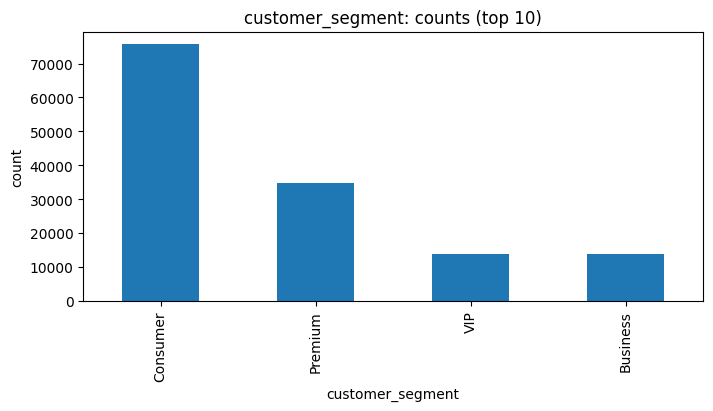

In [42]:
explore_column(order_df,'customer_segment')

as i can see in the Customer_sengment the number of consumer are the mose count then premium then vip and business are almost same

                  orders   net_sales      profit  order_share_%  \
customer_segment                                                  
Consumer           62211  79281384.8  33863806.2           54.8   
Premium            28544  35844446.9  14019935.6           25.1   
Business           11298  14451187.2   6133072.5            9.9   
VIP                11506  14618819.6   5741654.7           10.1   

                  sales_share_%  profit_share_%  profit_per_order  \
customer_segment                                                    
Consumer                   55.0            56.7             544.3   
Premium                    24.9            23.5             491.2   
Business                   10.0            10.3             542.8   
VIP                        10.1             9.6             499.0   

                  weighted_margin_%  
customer_segment                     
Consumer                       42.7  
Premium                        39.1  
Business                      

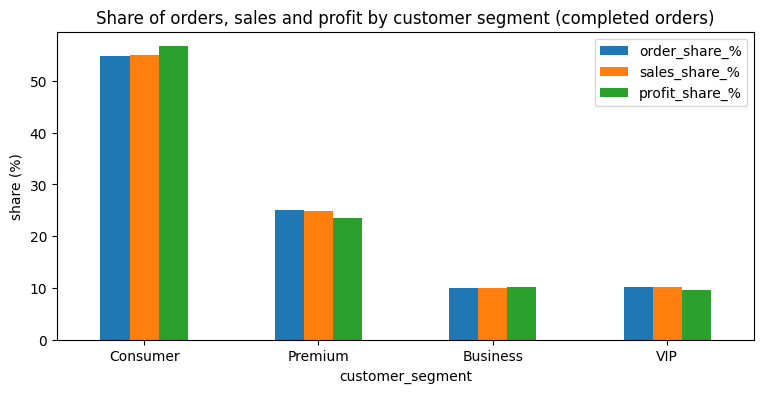

In [43]:
Customer_sengment_order_status = completed_order_df.groupby("customer_segment")
Customer_sengment_order_status

tabel_ = pd.DataFrame({
    'orders':Customer_sengment_order_status.size(),
    "net_sales":Customer_sengment_order_status['net_sales'].sum(),
    'profit':Customer_sengment_order_status['profit'].sum()
})

tabel_["order_share_%"] = tabel_["orders"] / tabel_["orders"].sum() * 100
tabel_["sales_share_%"] = tabel_["net_sales"] / tabel_["net_sales"].sum() * 100
tabel_["profit_share_%"] = tabel_["profit"] / tabel_["profit"].sum() * 100
tabel_["profit_per_order"] = tabel_["profit"] / tabel_["orders"]
tabel_["weighted_margin_%"] = tabel_["profit"] / tabel_["net_sales"] * 100


print(tabel_.sort_values("profit", ascending=False).round(1))
print("Check, shares add up to 100:", tabel_["profit_share_%"].sum().round(2))

share = tabel_[["order_share_%", "sales_share_%", "profit_share_%"]].sort_values("profit_share_%", ascending=False)
ax = share.plot(kind="bar", figsize=(9, 4))
ax.set_ylabel("share (%)")
ax.set_title("Share of orders, sales and profit by customer segment (completed orders)")
plt.xticks(rotation=0)
plt.show()

In [44]:
d = completed_order_df.copy()
d["discount_pct"] = d["discount_amount"] / d["gross_sales"] * 100

g = d.groupby("customer_segment")
why = pd.DataFrame({
    "gross_per_order": g["gross_sales"].mean(),
    "net_per_order": g["net_sales"].mean(),
    "avg_discount_pct": g["discount_pct"].mean(),
    "discount_per_order": g["discount_amount"].mean(),
    "cost_per_order": g["product_cost"].mean(),
    "shipping_per_order": g["shipping_cost"].mean(),
    "tax_per_order": g["tax_amount"].mean(),
    "quantity": g["quantity"].mean(),
    "coupon_share_%": g["has_coupon"].mean() * 100,
    "neg_profit_share_%": g["profit"].apply(lambda s: (s < 0).mean() * 100),
}).round(1)
print(why)

# How profit is built: which formula matches? (tests only, nothing is changed)
for name, est in {
    "net - cost": d["net_sales"] - d["product_cost"],
    "net - tax - shipping - cost": d["net_sales"] - d["tax_amount"] - d["shipping_cost"] - d["product_cost"],
    "gross - discount - cost": d["gross_sales"] - d["discount_amount"] - d["product_cost"],
}.items():
    print(name, "| max abs diff vs profit:", round((est - d["profit"]).abs().max(), 2))

                  gross_per_order  net_per_order  avg_discount_pct  \
customer_segment                                                     
Business                   1377.8         1279.1              15.8   
Consumer                   1368.8         1274.4              15.7   
Premium                    1450.0         1255.8              20.3   
VIP                        1463.1         1270.5              20.4   

                  discount_per_order  cost_per_order  shipping_per_order  \
customer_segment                                                           
Business                       245.4           711.3                25.0   
Consumer                       240.9           705.0                25.0   
Premium                        331.1           747.4                17.2   
VIP                            332.4           754.3                17.3   

                  tax_per_order  quantity  coupon_share_%  neg_profit_share_%  
customer_segment                          

In [45]:
ct = pd.crosstab(order_df["customer_segment"], order_df["order_status"])
r = pd.DataFrame({
    "orders": ct.sum(axis=1),
    "return_rate_%": ct["Returned"] / (ct["Completed"] + ct["Returned"]) * 100,
    "cancel_rate_%": ct["Cancelled"] / ct.sum(axis=1) * 100,
}).round(2)
print(r)

                  orders  return_rate_%  cancel_rate_%
customer_segment                                      
Business           13777           7.92           6.00
Consumer           75636           7.68           6.02
Premium            34746           7.70           6.18
VIP                13957           7.51           6.25


Customer segment vs profit (Completed orders, n = 113,559; table: order_df)

Consumer accounts for 54.8% of orders, Premium 25.1%, VIP 10.1% and Business 9.9%.
Profit per order is 544.3 (Consumer), 542.8 (Business), 499.0 (VIP) and 491.2 (Premium). Weighted margin is 42.7%, 42.4%, 39.3% and 39.1%.
Consumer’s profit share (56.7%) is about 2 percentage points above its order share; Premium’s (23.5%) is about 1.6 points below its order share.
Interpretation: Premium and VIP orders yield about 10% less profit per order (about 3.5 percentage points lower margin) than Consumer and Business orders, although order values are similar.
Open question: why? Possible factors are higher discounts, higher costs or a different product mix, but none of these has been checked yet.
Limitation: descriptive only, averages per order, and the table is order-level.

In [46]:
d = completed_order_df.copy()

# 1. Does profit = net_sales - product_cost - shipping_cost?
est = d["net_sales"] - d["product_cost"] - d["shipping_cost"]
print("max abs diff vs profit:", round((est - d["profit"]).abs().max(), 4))

# 2. Is product_cost a fixed share of gross_sales at order level?
ratio = d["product_cost"] / d["gross_sales"]
print(ratio.describe().round(4))

# 3. Per-order bridge by segment
b = d.groupby("customer_segment")[["gross_sales", "discount_amount", "tax_amount",
                                   "product_cost", "shipping_cost", "profit"]].mean()
b["rebuilt_profit"] = b["gross_sales"] - b["discount_amount"] + b["tax_amount"] - b["product_cost"]
b["discount_%_of_gross"] = b["discount_amount"] / b["gross_sales"] * 100
b["cost_%_of_gross"] = b["product_cost"] / b["gross_sales"] * 100
print(b.round(1).T)

max abs diff vs profit: 0.0
count    113559.0000
mean          0.4863
std           0.0816
min           0.2507
25%           0.4278
50%           0.4865
75%           0.5431
max           0.6995
dtype: float64
customer_segment     Business  Consumer  Premium     VIP
gross_sales            1377.8    1368.8   1450.0  1463.1
discount_amount         245.4     240.9    331.1   332.4
tax_amount              121.8     121.4    119.8   122.6
product_cost            711.3     705.0    747.4   754.3
shipping_cost            25.0      25.0     17.2    17.3
profit                  542.8     544.3    491.2   499.0
rebuilt_profit          542.8     544.3    491.2   499.0
discount_%_of_gross      17.8      17.6     22.8    22.7
cost_%_of_gross          51.6      51.5     51.5    51.6


Customer segment vs profit (Completed orders, n = 113,559; table: order_df)

Profit per order is 544.3 (Consumer), 542.8 (Business), 499.0 (VIP) and 491.2 (Premium); weighted margin is 42.7%, 42.4%, 39.3% and 39.1%.
Premium and VIP orders have a higher list value (gross 1,450 and 1,463 vs about 1,370) and a deeper discount (about 22.8% of gross vs about 17.7%), so net sales per order are not higher (1,256 and 1,271 vs 1,274 and 1,279).
Product cost is about 51.5% of gross sales in every segment, so the higher cost per order in Premium and VIP comes from larger list-value baskets, not from a different cost structure.
Negative-profit orders are 2.3% to 2.5% of Premium and VIP orders against 0.4% for Consumer and Business.
Return rates (7.51% to 7.92%) and cancellation rates (6.00% to 6.25%) are within 0.25 percentage points of the overall rates in all segments.
Interpretation: deeper discounts on larger baskets are consistent with the lower margin in Premium and VIP; segment does not appear to affect returns or cancellations.
Open question: why do these segments receive deeper discounts (loyalty offers, policy, product mix)? Does the extra discount produce extra volume?
Limitation: based on averages; profit appears to include collected tax (see formula check), which inflates margins in every segment.

### 5.7 Delivery days

Column: delivery_days | dtype: float64 | unique: 15 | nulls: 24557 (17.8%)
Examples: [ 3. 10.  2.  6.  9.]
delivery_days
NaN    17.8
3.0    12.5
5.0    10.1
6.0     9.7
7.0     9.6
1.0     9.4
4.0     7.8
2.0     6.7
0.0     4.8
8.0     3.8
Name: count, dtype: float64


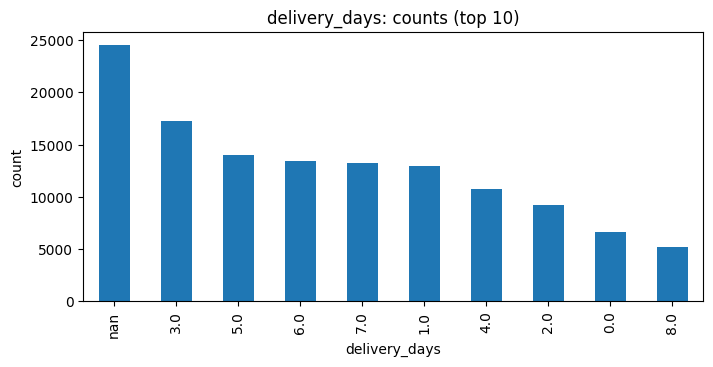

In [47]:
explore_column(order_df,"delivery_days")

## 6. Scanning columns for differences
For each categorical column: how much do profit per order, margin, return rate and cancellation rate differ between groups?

In [48]:
def scan(completed, delivered, all_orders, cols, min_n=500):
    """For each categorical column: how much do profit per order, margin, return rate
    and cancellation rate differ between its groups? Groups smaller than min_n are ignored."""
    rows = []
    for c in cols:
        g = completed.groupby(c, observed=True)
        t = pd.DataFrame({"n": g.size(), "ppo": g["profit"].mean(),
                          "margin": g["profit"].sum() / g["net_sales"].sum() * 100})
        t = t[t["n"] >= min_n]
        r = delivered.groupby(c, observed=True)["returned"].agg(["size", "mean"])
        r = r[r["size"] >= min_n]["mean"] * 100
        k = all_orders.groupby(c, observed=True)["order_status"].agg(
            n="size", cancel=lambda s: (s == "Cancelled").mean() * 100)
        k = k[k["n"] >= min_n]["cancel"]
        if len(t) < 2:
            continue
        rows.append({
            "column": c, "groups": len(t),
            "profit_per_order_spread_%": (t["ppo"].max() - t["ppo"].min()) / t["ppo"].mean() * 100,
            "margin_range_pts": t["margin"].max() - t["margin"].min(),
            "return_range_pts": r.max() - r.min() if len(r) > 1 else np.nan,
            "cancel_range_pts": k.max() - k.min() if len(k) > 1 else np.nan,
        })
    return pd.DataFrame(rows).set_index("column").sort_values("profit_per_order_spread_%", ascending=False).round(2)

completed = order_df[order_df["order_status"] == "Completed"]
delivered = order_df[order_df["order_status"].isin(["Completed", "Returned"])]

skip = {"order_status", "return_status", "return_reason", "returned"}     # outcomes, not explanations
cat_cols = [c for c in order_df.columns
            if 2 <= order_df[c].nunique() <= 20 and c not in skip]
print(cat_cols)
print(scan(completed, delivered, order_df, cat_cols))

['sales_channel', 'gender', 'customer_segment', 'customer_type', 'customer_country', 'region', 'payment_method', 'payment_status', 'currency', 'shipping_method', 'warehouse', 'delivery_days', 'estimated_delivery_days', 'delivery_status', 'review_sentiment', 'marketing_channel', 'campaign_name', 'is_repeat_customer', 'customer_order_count', 'has_coupon', 'has_campaign']
                         groups  profit_per_order_spread_%  margin_range_pts  \
column                                                                         
currency                      7                      29.50              8.10   
customer_country              7                      29.50              8.10   
review_sentiment              3                      23.22              1.36   
region                        5                      20.34              4.84   
campaign_name                17                      12.07              1.23   
customer_segment              4                      10.24          

## 7. EDA toolkit demo
Using the `EDA` class defined in section 1.

In [49]:
eda = EDA(order_df, name="order_df")
done = eda.subset(lambda d: d["order_status"] == "Completed", name="completed")

[completed] sales_channel | dtype: object | unique: 4 | nulls: 0 (0.0%)
Examples: ['Mobile App' 'Website' 'Social Media' 'Marketplace']
sales_channel
Mobile App      40.1
Website         34.9
Marketplace     15.0
Social Media    10.1
Name: count, dtype: float64


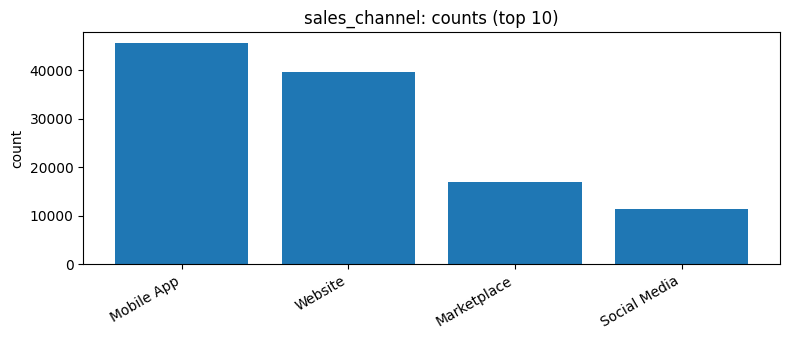

[completed] net_sales | dtype: float64 | unique: 95344 | nulls: 0 (0.0%)
Examples: [ 945.4  2018.41  468.35  546.52 2785.27]
count              113559.00
nulls                   0.00
mean                 1269.79
median                942.85
mode                  166.32
std                  1152.81
cv                      0.91
min                     5.80
p5                    112.29
q1                    443.22
q3                   1732.82
p95                  3563.86
max                 16218.00
iqr                  1289.61
skew                    1.87
excess_kurtosis         5.29
outlier_share_%         4.56


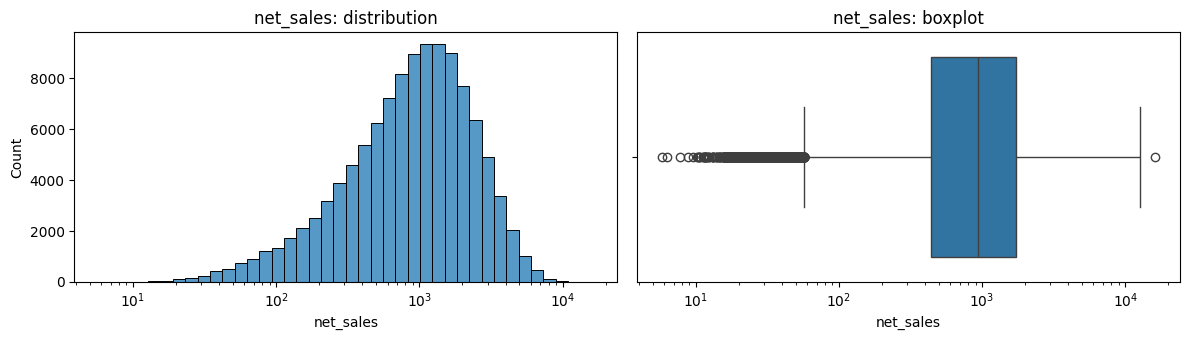

In [50]:
done.univariate("sales_channel")    # one column at a time
done.univariate("net_sales", log=True)

[completed] order_date | dtype: datetime64[ns] | unique: 1826 | nulls: 0 (0.0%)
Examples: <DatetimeArray>
['2023-11-06 00:00:00', '2025-12-24 00:00:00', '2021-07-05 00:00:00',
 '2023-01-21 00:00:00', '2022-05-13 00:00:00']
Length: 5, dtype: datetime64[ns]
Range: 2021-01-01 00:00:00 to 2025-12-31 00:00:00


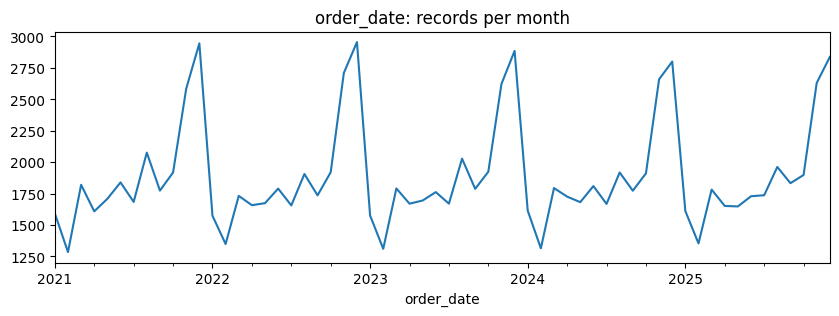

[completed] order_time | dtype: object | unique: 63357 | nulls: 0 (0.0%)
Examples: ['16:37:47' '01:22:36' '14:24:21' '07:20:26' '09:46:21']
-> High-cardinality column, showing only the top 10
order_time
14:55:55    0.0
13:10:28    0.0
20:00:26    0.0
21:20:58    0.0
00:22:58    0.0
20:50:32    0.0
17:41:53    0.0
16:33:10    0.0
21:59:39    0.0
12:49:53    0.0
Name: count, dtype: float64


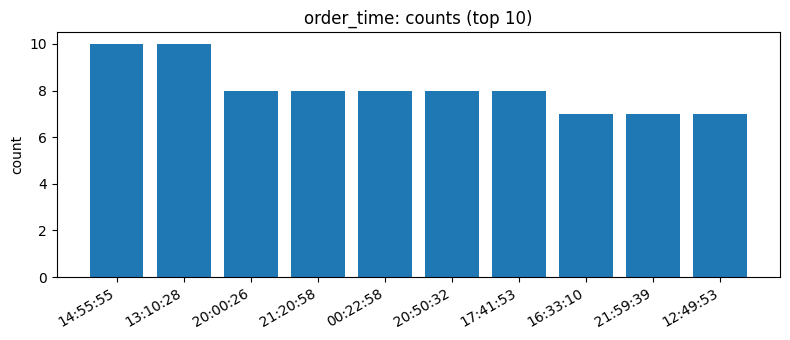

[completed] order_status | dtype: object | unique: 1 | nulls: 0 (0.0%)
Examples: ['Completed']
order_status
Completed    100.0
Name: count, dtype: float64


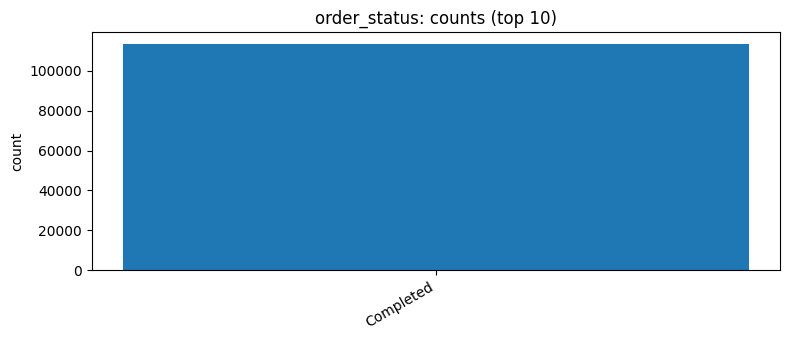

[completed] sales_channel | dtype: object | unique: 4 | nulls: 0 (0.0%)
Examples: ['Mobile App' 'Website' 'Social Media' 'Marketplace']
sales_channel
Mobile App      40.1
Website         34.9
Marketplace     15.0
Social Media    10.1
Name: count, dtype: float64


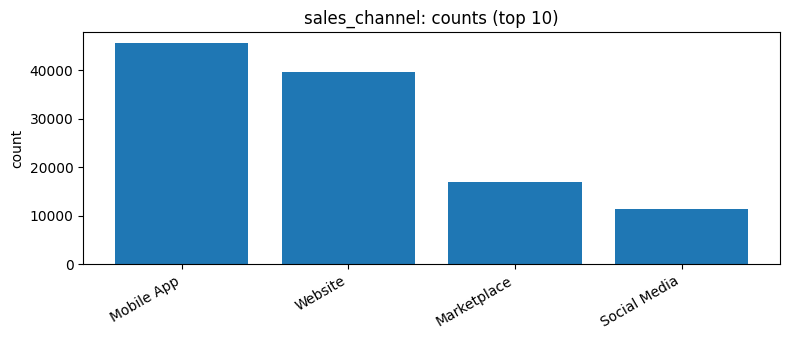

[completed] customer_age | dtype: int64 | unique: 57 | nulls: 0 (0.0%)
Examples: [55 26 69 65 34]
count              113559.00
nulls                   0.00
mean                   45.85
median                 46.00
mode                   19.00
std                    16.46
cv                      0.36
min                    18.00
p5                     20.00
q1                     32.00
q3                     60.00
p95                    72.00
max                    74.00
iqr                    28.00
skew                    0.01
excess_kurtosis        -1.20
outlier_share_%         0.00


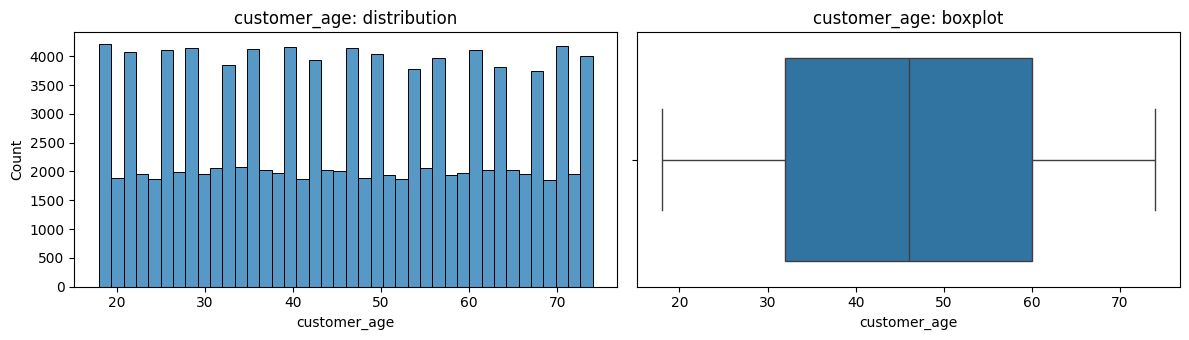

[completed] gender | dtype: object | unique: 3 | nulls: 0 (0.0%)
Examples: ['Male' 'Female' 'Non-Binary']
gender
Female        48.1
Male          48.0
Non-Binary     3.9
Name: count, dtype: float64


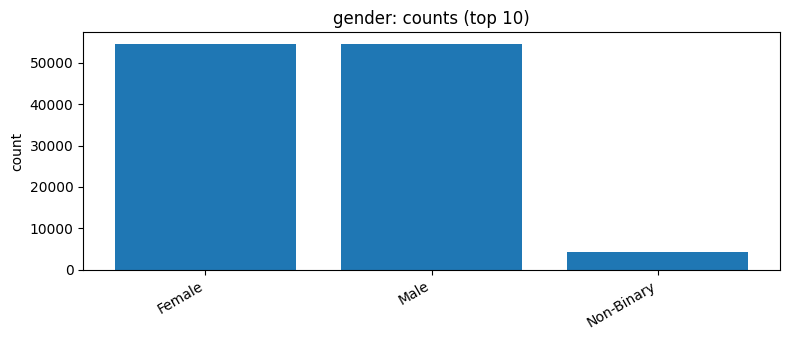

[completed] customer_segment | dtype: object | unique: 4 | nulls: 0 (0.0%)
Examples: ['Consumer' 'Premium' 'VIP' 'Business']
customer_segment
Consumer    54.8
Premium     25.1
VIP         10.1
Business     9.9
Name: count, dtype: float64


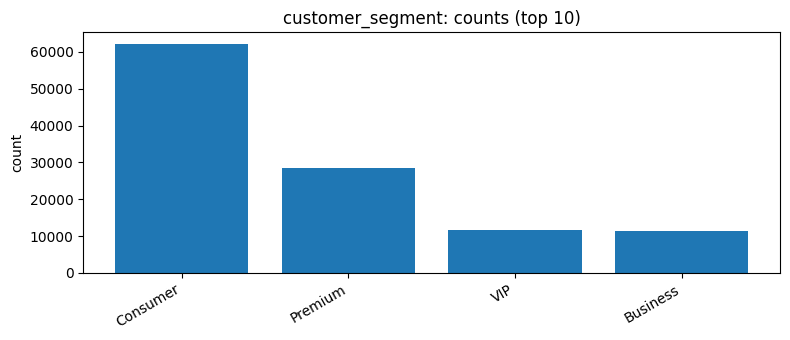

[completed] customer_type | dtype: object | unique: 3 | nulls: 0 (0.0%)
Examples: ['Loyal' 'Returning' 'New']
customer_type
Loyal        93.7
Returning     6.0
New           0.2
Name: count, dtype: float64


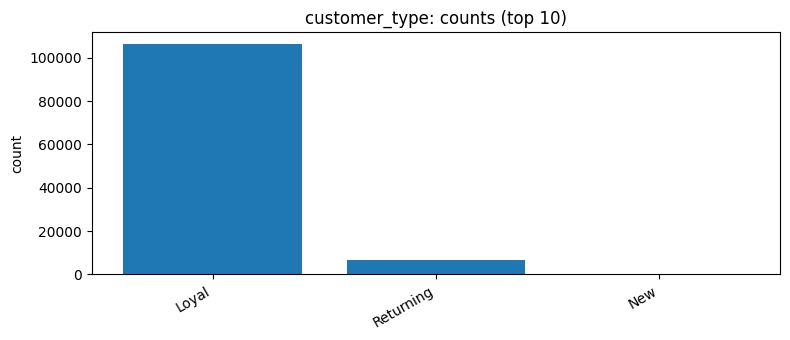

In [51]:
# Several columns in a row (skip IDs, names and free text)
skip = {"order_id", "customer_id", "customer_name", "customer_review", "coupon_code", "customer_postal_code"}
cols = [c for c in done.df.columns if c not in skip]
for c in cols[:8]:
    done.univariate(c)

[completed] region (categorical)  vs  profit (numeric)


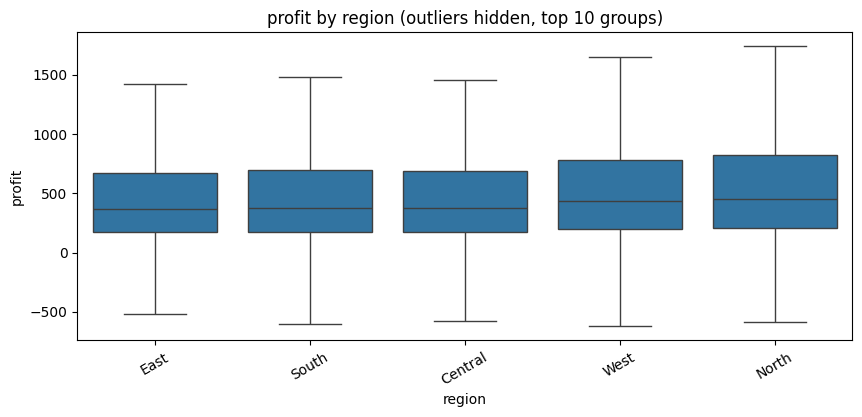

         count    mean  median     std
region                                
North    13633  599.73  447.16  550.83
West     21621  571.62  431.86  519.66
Central  24259  498.88  376.92  460.85
South    36205  507.04  376.17  475.48
East     17841  491.20  369.65  456.27
[completed] customer_segment (categorical)  vs  net_sales (numeric)


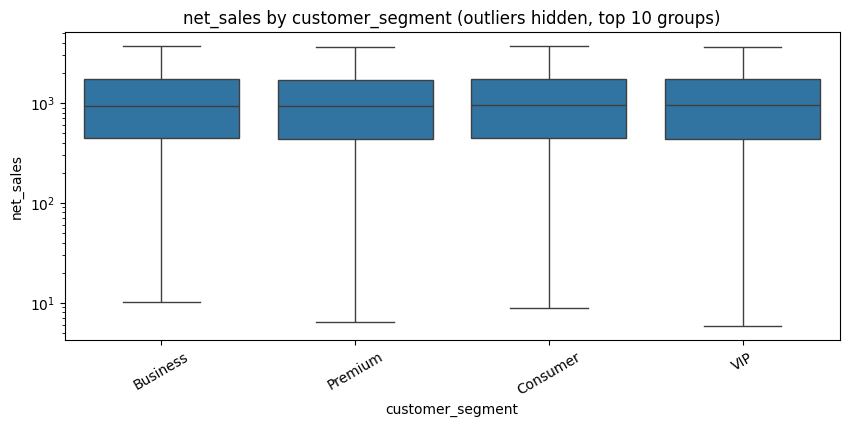

                  count     mean  median      std
customer_segment                                 
VIP               11506  1270.54  957.87  1141.24
Consumer          62211  1274.39  945.06  1161.13
Premium           28544  1255.76  936.32  1133.37
Business          11298  1279.09  935.18  1167.06
[completed] region (categorical)  vs  customer_segment (categorical)


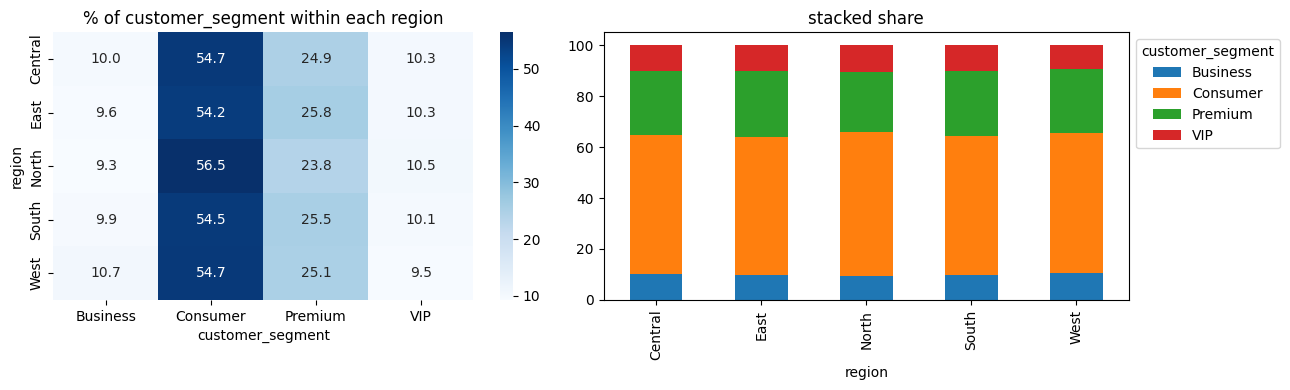

customer_segment  Business  Consumer  Premium    VIP     All
region                                                      
Central               2431     13280     6044   2504   24259
East                  1717      9675     4606   1843   17841
North                 1265      7697     3241   1430   13633
South                 3578     19727     9228   3672   36205
West                  2307     11832     5425   2057   21621
All                  11298     62211    28544  11506  113559
[completed] order_date (date)  vs  net_sales (numeric)


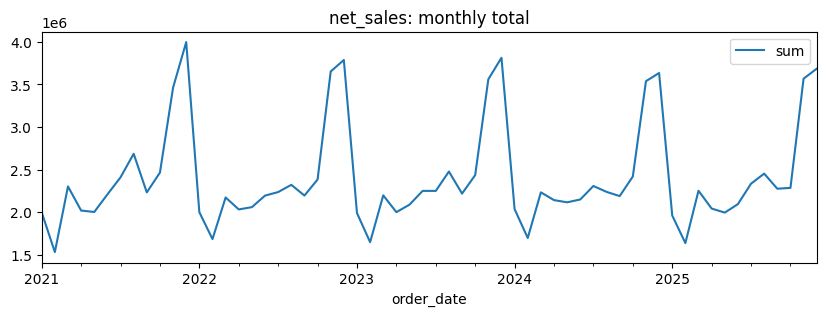

                   sum         mean  count
order_date                                
2025-08-31  2451824.76  1249.655841   1962
2025-09-30  2274854.37  1241.055303   1833
2025-10-31  2284572.08  1203.673383   1898
2025-11-30  3565834.89  1355.830757   2630
2025-12-31  3682587.48  1298.056919   2837


In [52]:
done.bivariate("region", "profit")                        # categorical vs numeric: boxplot + group table
done.bivariate("customer_segment", "net_sales", log=True) # log scale helps with skewed money columns
done.bivariate("region", "customer_segment")              # categorical vs categorical: % heatmap + counts
done.bivariate("order_date", "net_sales")

[completed] discount_pct (numeric)  vs  profit_margin_percentage (numeric)


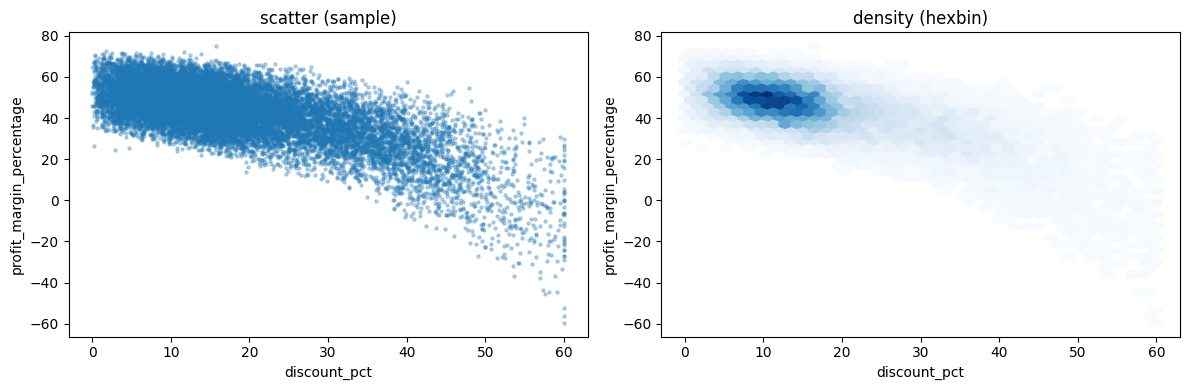

Spearman: -0.575 | Pearson: -0.7 | n = 113559


In [53]:
done.df["discount_pct"] = done.df["discount_amount"] / done.df["gross_sales"] * 100
done.bivariate("discount_pct", "profit_margin_percentage")   # numeric vs numeric: scatter, hexbin, correlation

## 8. Descriptive statistics

In [54]:
order_df.columns

Index(['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_id', 'customer_name', 'customer_age', 'gender',
       'customer_segment', 'customer_type', 'customer_city', 'customer_state',
       'customer_country', 'region', 'customer_postal_code', 'payment_method',
       'payment_status', 'currency', 'shipping_method', 'warehouse',
       'delivery_days', 'estimated_delivery_days', 'delivery_status',
       'return_status', 'return_reason', 'customer_rating', 'review_sentiment',
       'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code',
       'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity',
       'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost',
       'net_sales', 'product_cost', 'profit', 'profit_margin_percentage',
       'customer_lifetime_value', 'is_repeat_customer', 'customer_order_count',
       'customer_acquisition_cost', 'returned', 'has_coupon', 'has_campaign'],
      dtype='object')

In [55]:
completes_status = order_df[order_df["order_status"]=='Completed']

num_cols = ["quantity", "gross_sales", "discount_amount", "net_sales",
            "profit", "profit_margin_percentage", "delivery_days"]

# this is give the information about the completed data its give the data central tendancy and spread of the data

desc = completes_status[num_cols].describe().T

desc['median'] = completes_status[num_cols].median()
desc['mode'] = completes_status[num_cols].mode().iloc[0]
desc['IQR'] = desc['75%'] - desc['25%']
desc['cv'] = desc['std'] / desc['mean']

print(desc.round(2),'\n')

print(pd.DataFrame({'Skewed':completes_status[num_cols].skew(),    # tell the shape of the coulms the columns is skewed or kurtosis
      'kurtosis':completes_status[num_cols].kurt()}).round(2))

# percentile
percentile_info = completes_status[['net_sales','profit']].quantile([.01, .05, .25, .5, .75, .95, .99]).round(1)


print(percentile_info)



                             count     mean      std      min     25%  \
quantity                  113559.0     5.71     3.42     1.00    3.00   
gross_sales               113559.0  1399.65  1311.55     6.31  465.60   
discount_amount           113559.0   273.31   394.85     0.00   51.04   
net_sales                 113559.0  1269.79  1152.81     5.80  443.22   
profit                    113559.0   526.23   489.39 -1281.59  182.56   
profit_margin_percentage  113559.0    43.72    13.26   -59.55   37.52   
delivery_days             113559.0     4.56     2.81     0.00    2.00   

                              50%      75%       max   median    mode  \
quantity                     5.00     8.00     24.00     5.00    4.00   
gross_sales               1014.51  1910.27  16051.19  1014.51  111.12   
discount_amount            133.05   320.71   6759.02   133.05   10.89   
net_sales                  942.85  1732.82  16218.00   942.85  166.32   
profit                     393.18   721.95   6209.

<Axes: xlabel='net_sales', ylabel='Density'>

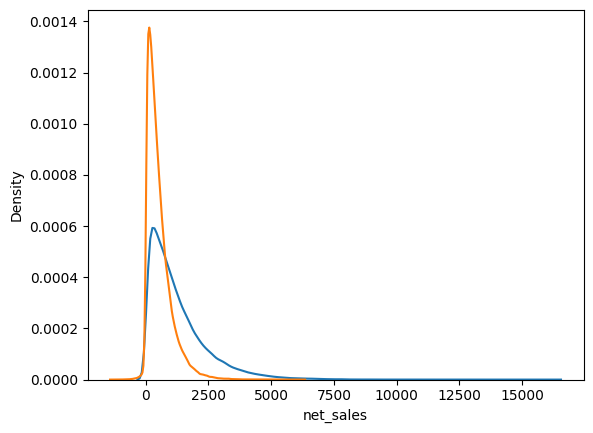

In [56]:
sns.kdeplot(completes_status['net_sales'])
sns.kdeplot(completes_status['profit'])

## 9. Additional column checks

### 9.1 Currency and country

Column: currency | dtype: object | unique: 7 | nulls: 0 (0.0%)
Examples: ['USD' 'EUR' 'INR' 'CAD' 'GBP']
currency
USD    59.8
GBP    14.7
EUR     8.4
CAD     5.1
AUD     4.9
INR     4.1
AED     3.0
Name: count, dtype: float64


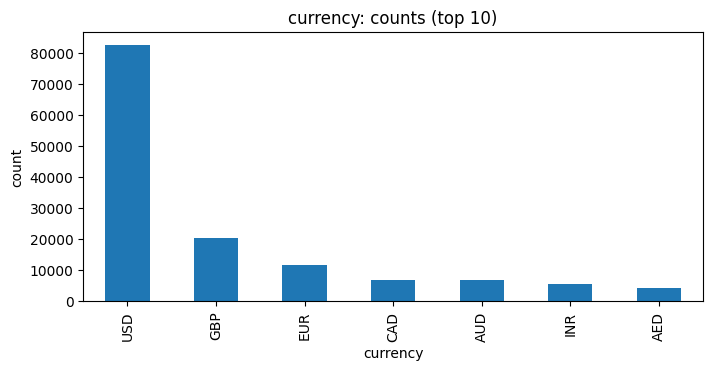

In [57]:
explore_column(order_df,'currency')

Question: Are gross_sales, net_sales and profit in one common unit across all currencies, or in each order’s own currency? Does the currency match the customer’s country?
Why: If amounts are in local currencies, every sum, average and margin is wrong.
Check: Mean and median net_sales by currency; crosstab of customer_country vs currency.

In [58]:
currency_df = completed_order_df.groupby('currency')[["gross_sales", "net_sales", "profit"]].agg(["median", "mean"]).round(1)

print(currency_df,'\n')

print(pd.crosstab(order_df['customer_country'],order_df['currency']))

         gross_sales         net_sales         profit       
              median    mean    median    mean median   mean
currency                                                    
AED           1024.3  1423.1     919.0  1231.9  349.2  467.1
AUD           1027.0  1411.0     954.4  1280.4  392.3  516.3
CAD           1025.9  1391.9     972.5  1286.5  408.9  543.0
EUR           1019.0  1405.6    1014.1  1370.4  466.0  628.3
GBP           1030.8  1396.9    1034.8  1369.7  476.6  630.3
INR            993.5  1400.0     984.5  1340.3  463.2  605.4
USD           1010.3  1398.0     908.3  1226.0  363.7  483.4 

currency           AED   AUD   CAD    EUR    GBP   INR    USD
customer_country                                             
Australia            0  6794     0      0      0     0      0
Canada               0     0  7015      0      0     0      0
Germany              0     0     0  11593      0     0      0
India                0     0     0      0      0  5707      0
UAE             

In [59]:
d = completed_order_df.copy()
d["discount_pct"] = d["discount_amount"] / d["gross_sales"] * 100
print(d.groupby("customer_country")[["discount_pct", "product_cost", "shipping_cost"]].mean().round(1))
print(pd.crosstab(d["customer_country"], d["customer_segment"], normalize="index").mul(100).round(1))

                  discount_pct  product_cost  shipping_cost
customer_country                                           
Australia                 17.5         729.1           35.1
Canada                    17.7         716.5           27.0
Germany                   17.2         723.6           18.5
India                     17.4         721.1           13.8
UAE                       17.4         733.8           31.0
UK                        17.3         721.0           18.3
USA                       17.4         720.2           22.5
customer_segment  Business  Consumer  Premium   VIP
customer_country                                   
Australia             11.5      53.4     24.5  10.5
Canada                 9.7      53.6     26.7  10.0
Germany                9.4      55.8     25.2   9.6
India                 11.6      53.1     24.9  10.4
UAE                    9.1      53.7     26.9  10.4
UK                     9.9      55.2     24.2  10.7
USA                    9.9      54.9     25.

In [60]:
d = completed_order_df.copy()
d["tax_pct"] = d["tax_amount"] / (d["gross_sales"] - d["discount_amount"]) * 100
print(d.groupby("customer_country")[["tax_amount", "tax_pct"]].mean().round(1))

                  tax_amount  tax_pct
customer_country                     
Australia              113.2     10.0
Canada                 144.9     13.0
Germany                215.9     19.0
India                  202.4     18.0
UAE                     57.2      5.0
UK                     225.2     20.0
USA                     78.7      7.0


Discount (17.2% to 17.7% of gross), product cost (716 to 734) and customer segment mix are almost the same in every country, so they do not explain the lower profit in USA, UAE and Australia. Shipping cost differs (13.8 in India to 35.1 in Australia) but the gap is too small.
Open question: is the difference caused by tax? Net sales and profit appear to include collected tax.

### 9.2 Delivery status vs order status

Column: delivery_status | dtype: object | unique: 4 | nulls: 0 (0.0%)
Examples: ['On Time' 'Delayed' 'Cancelled' 'Early']
delivery_status
On Time      62.9
Cancelled    17.8
Delayed      12.2
Early         7.1
Name: count, dtype: float64


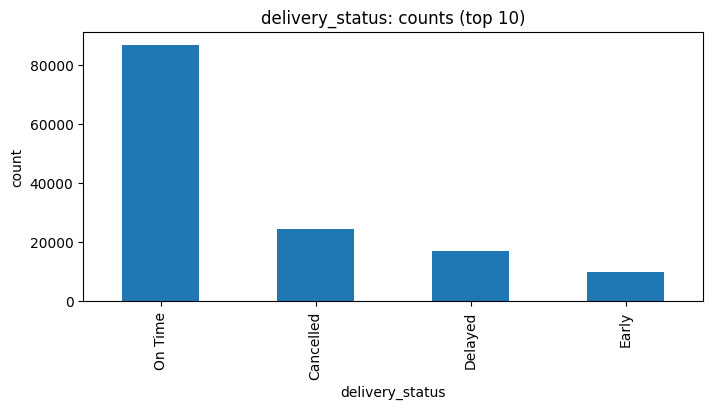

In [63]:
explore_column(order_df,'delivery_status')

In [64]:
print(pd.crosstab(order_df['delivery_status'],order_df['order_status']))

order_status     Cancelled  Completed  Pending  Returned
delivery_status                                         
Cancelled             8398          0     6697      9462
Delayed                  0      16886        0         0
Early                    0       9757        0         0
On Time                  0      86916        0         0


delivery_status is not independent of order_status. All 113,559 Completed orders have a timing value (On Time 76.5%, Delayed 14.9%, Early 8.6%). Every Cancelled, Pending and Returned order (24,557) has delivery_status = "Cancelled", including 9,462 Returned orders that must have been delivered first.

**Decision:** use delivery_status only on Completed orders.
Open question: do the other delivery columns (delivery_days) have values for Returned orders?
Limitation: delivery timing cannot be compared between returned and non-returned orders.

### 9.3 Delivery status vs customer rating

In [65]:
order_df['customer_rating'].isnull().sum()

np.int64(24557)

In [66]:
delivery_by_rating = order_df.groupby('delivery_status')['customer_rating'].agg(['mean','count']).round(1)
print(delivery_by_rating)

                 mean  count
delivery_status             
Cancelled         NaN      0
Delayed           3.2  16886
Early             4.0   9757
On Time           3.7  86916


[completed] customer_rating | dtype: float64 | unique: 35 | nulls: 0 (0.0%)
Examples: [3.5 3.6 4.3 3.  3.3]
count              113559.00
nulls                   0.00
mean                    3.68
median                  3.70
mode                    3.70
std                     0.48
cv                      0.13
min                     1.60
p5                      2.90
q1                      3.40
q3                      4.00
p95                     4.50
max                     5.00
iqr                     0.60
skew                   -0.12
excess_kurtosis        -0.03
outlier_share_%         1.04


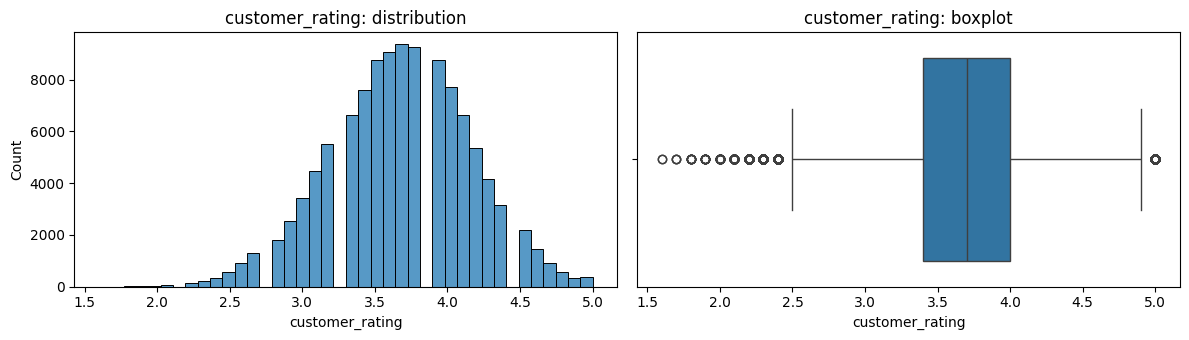

In [68]:
done.univariate("customer_rating")

In [69]:
print(order_df['customer_rating'].describe())

count    113559.000000
mean          3.677015
std           0.483672
min           1.600000
25%           3.400000
50%           3.700000
75%           4.000000
max           5.000000
Name: customer_rating, dtype: float64


In [71]:
d = order_df[order_df["order_status"] == "Completed"].copy()

# 1. Full rating distribution per delivery status (not only the mean)
print(d["customer_rating"].describe().round(2))                       # confirm the scale (min, max)
dist = pd.crosstab(d["delivery_status"], d["customer_rating"], normalize="index") * 100
print(dist.round(1))
print(d.groupby("delivery_status")["customer_rating"].agg(["count", "mean", "median", "std"]).round(2))

# 2. How is delivery_status defined? Compare with delivery_days minus estimated_delivery_days
d["days_vs_estimate"] = d["delivery_days"] - d["estimated_delivery_days"]
print(d.groupby("delivery_status")["days_vs_estimate"].describe().round(2))

# 3. Rating by days versus the estimate (numeric view of the same idea)
print(d.groupby("days_vs_estimate")["customer_rating"].agg(["count", "mean"]).round(2))

# 4. What is associated with delayed deliveries?
d["delayed"] = (d["delivery_status"] == "Delayed").astype(int)
for c in ["shipping_method", "warehouse", "region", "customer_segment"]:
    t = d.groupby(c)["delayed"].agg(["size", "mean"])
    t["delayed_%"] = (t["mean"] * 100).round(1)
    print(t[t["size"] >= 500].sort_values("delayed_%", ascending=False).head(8)[["size", "delayed_%"]], "\n")

count    113559.00
mean          3.68
std           0.48
min           1.60
25%           3.40
50%           3.70
75%           4.00
max           5.00
Name: customer_rating, dtype: float64
customer_rating  1.6  1.7  1.8  1.9  2.0  2.1  2.2  2.3  2.4  2.5  ...  4.1  \
delivery_status                                                    ...        
Delayed          0.0  0.0  0.0  0.1  0.2  0.4  0.7  1.0  1.4  2.4  ...  1.2   
Early            0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  8.9   
On Time          0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.1  0.2  ...  6.4   

customer_rating  4.2  4.3  4.4  4.5  4.6  4.7  4.8  4.9  5.0  
delivery_status                                               
Delayed          0.8  0.4  0.2  0.2  0.1  0.0  0.0  0.0  0.0  
Early            8.5  7.6  6.3  5.1  3.8  2.6  1.9  1.2  1.6  
On Time          5.0  3.9  2.9  1.9  1.2  0.8  0.4  0.3  0.3  

[3 rows x 35 columns]
                 count  mean  median   std
delivery_status                  

### Observation: Delivery status vs customer rating

**Subset:** Completed orders only (n = 113,559). Returned/cancelled orders have no rating.

**1. Rating scale:** 1.6 to 5.0, decimal values (35 distinct), mean 3.68, median 3.7, std 0.48.

**2. By delivery status:**

| Status | Orders | Mean | Median | Std |
|---|---|---|---|---|
| Delayed | 16,886 | 3.22 | 3.2 | 0.44 |
| On Time | 86,916 | 3.73 | 3.7 | 0.44 |
| Early | 9,757 | 4.02 | 4.0 | 0.43 |

Early vs Delayed gap is about 0.8 points. Spread is the same in all three groups.

**3. Effect of days:** Rating changes in a step by status, not gradually by days. +1 to +4 days late all sit near 3.22.

**4. Where delay comes from:** 14.9% of orders are delayed. This share barely changes by shipping method, region, segment or warehouse (14.5% to 15.8%), so none of these columns explains it.

**5. What I cannot claim:**
- Delay causes lower ratings (only an association).
- Anything about returns (no rating for returned orders).
- Anything about all customers (Completed orders only).

**Open check:** 511 orders have days_vs_estimate = 0 but status "Early". To be confirmed.

### 9.4 Tax and profit

In [87]:
print((completed_order_df["profit"] < 0).mean())
print((completed_order_df["profit_ex_tax"] < 0).mean())

0.010822568004297326
0.02110797030618445


### Observation: Negative-profit orders after removing tax

**Subset:** Completed orders only (n = 113,559).

**1. Result:** the share of orders with negative profit is 1.08% with tax included (`profit`) and 2.11% after removing tax (`profit_ex_tax`), about twice as high.

**2. Interpretation:** collected tax was hiding losses on some orders. Using `profit` understates how many orders lose money.

**3. What I cannot claim:** why these orders lose money. This is only the overall share.

**Open question:** at what discount level do these orders appear, and which segment do they belong to? (see discount analysis)

In [85]:
print(completed_order_df.groupby("customer_country")[["profit", "profit_ex_tax"]].mean().round(1))

                  profit  profit_ex_tax
customer_country                       
Australia          516.3          403.1
Canada             543.0          398.1
Germany            628.3          412.5
India              605.4          403.1
UAE                467.1          409.9
UK                 630.3          405.1
USA                483.4          404.7


### Observation: Profit by country after removing tax

**Subset:** Completed orders only (n = 113,559).

**1. Result:** mean `profit_ex_tax` is between 398.1 (Canada) and 412.5 (Germany) in all 7 countries, a spread of about 3.6%. Mean `profit` (with tax) ranged from 467.1 (UAE) to 630.3 (UK), a spread of about 35%.

**2. Conclusion:** the difference in profit between countries was caused by tax, not by discount, cost or segment mix. After removing tax, country does not affect profit per order.

**3. What I cannot claim:** whether tax should be treated as revenue in the source system. This is based on averages per country.

**Decision:** use `profit_ex_tax` for profit analysis from here.

### 9.5 Discount and profit

**Question:** At what discount level does profit per order fall, and when does profit turn negative?

**Hypotheses:**
- **H1:** As discount percentage increases, profit per order and margin decrease.
- **H2:** Orders above a certain discount level have negative profit.
- **H3:** The lower profit in Premium and VIP is explained by their deeper discounts. Within the same discount band, their profit per order is similar to Consumer and Business.

**Why:** the segment analysis showed deeper discounts for Premium and VIP (about 22.8% of gross against about 17.7%) and lower margins.

**Check:** discount bands (0, 0-5, 5-10, 10-20, 20+%) using `profit_ex_tax`, with orders, profit per order, margin and negative-profit share. Then the same table split by segment.

**Observation:** (write after running the check)

count    113559.0
mean         17.4
std          11.6
min           0.0
25%           9.1
50%          14.3
75%          22.6
max          60.0
Name: discount_pct, dtype: float64
0


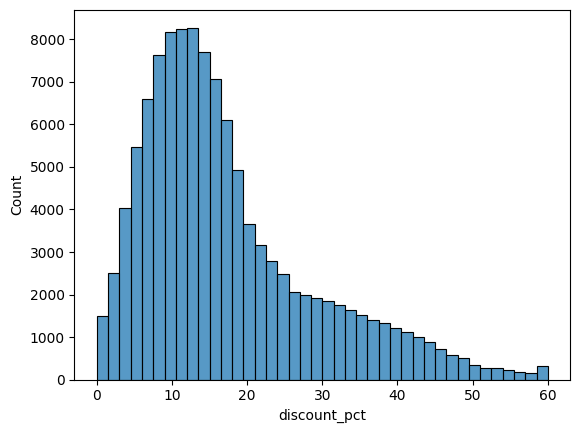

In [88]:
d = completed_order_df
print(d["discount_pct"].describe().round(1))
sns.histplot(d["discount_pct"], bins=40)


d["band"] = pd.cut(d["discount_pct"], [0, 5, 10, 15, 20, 25, 100], include_lowest=True)
print(d["band"].isna().sum())   # should be 0



**Band-wise table (H1 and H2)**

               orders  profit_per_order  margin_%  negative_%
band                                                         
(-0.001, 5.0]    9652             486.6      45.1         0.0
(5.0, 10.0]     23452             508.5      43.4         0.0
(10.0, 15.0]    26999             460.0      40.5         0.0
(15.0, 20.0]    19410             384.4      36.9         0.0
(20.0, 25.0]    10001             368.7      32.8         0.0
(25.0, 100.0]   24045             241.6      19.1        10.0


<Axes: xlabel='band'>

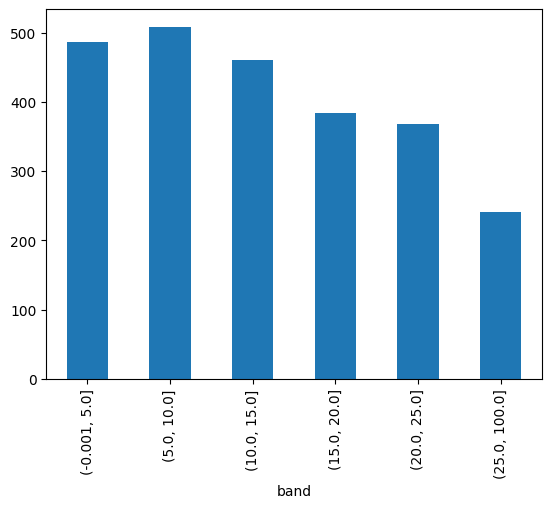

In [89]:
g = d.groupby("band", observed=True)
t = pd.DataFrame({
    "orders": g.size(),
    "profit_per_order": g["profit_ex_tax"].mean(),
    "margin_%": g["profit_ex_tax"].sum() / g["net_sales_ex_tax"].sum() * 100,
    "negative_%": g["profit_ex_tax"].apply(lambda s: (s < 0).mean() * 100),
}).round(1)
print(t)
t["profit_per_order"].plot(kind="bar")

**Band × segment (H3)**

In [90]:
print(d.pivot_table(index="band", columns="customer_segment", values="profit_ex_tax", aggfunc="mean", observed=True).round(1))
print(d.pivot_table(index="band", columns="customer_segment", values="profit_ex_tax", aggfunc="size", observed=True))

customer_segment  Business  Consumer  Premium    VIP
band                                                
(-0.001, 5.0]        478.1     493.3    475.9  469.5
(5.0, 10.0]          516.9     510.6    493.2  517.2
(10.0, 15.0]         452.3     457.3    468.6  467.6
(15.0, 20.0]         374.2     370.5    401.0  416.7
(20.0, 25.0]         376.0     386.0    354.4  357.2
(25.0, 100.0]        281.1     281.6    191.5  190.0
customer_segment  Business  Consumer  Premium   VIP
band                                               
(-0.001, 5.0]         1113      6040     1799   700
(5.0, 10.0]           2644     14779     4387  1642
(10.0, 15.0]          2961     16062     5633  2343
(15.0, 20.0]          1771     10113     5330  2196
(20.0, 25.0]           704      3896     3823  1578
(25.0, 100.0]         2105     11321     7572  3047


In [91]:
big = d[d["discount_pct"] > 25]
print(big.groupby("customer_segment")["discount_pct"].mean().round(1))
d["band2"] = pd.cut(d["discount_pct"], [25, 30, 35, 40, 100])
print(d.groupby("band2", observed=True)["profit_ex_tax"].agg(["size", "mean", lambda s: (s < 0).mean() * 100]).round(1))

customer_segment
Business    34.2
Consumer    34.1
Premium     38.6
VIP         38.5
Name: discount_pct, dtype: float64
           size   mean  <lambda_0>
band2                             
(25, 30]   6752  390.7         0.0
(30, 35]   5785  322.4         0.5
(35, 40]   4535  229.4         4.5
(40, 100]  6973   38.1        31.0


### Observation: Discount and profit

**Subset:** Completed orders only (n = 113,559); profit is `profit_ex_tax`.

**1. H1 (supported):** profit per order is flat up to 10% discount (487 to 509), then falls (460 at 10-15%, 384 at 15-20%, 369 at 20-25%) and is lowest above 25% (242). Margin falls steadily after 10%, from 43.4% to 19.1%.

**2. H2 (supported):** negative-profit orders appear only above 25% discount. Share of loss-making orders: 0.0% at 25-30%, 0.5% at 30-35%, 4.5% at 35-40% and 31.0% above 40%. About 90% of all loss-making orders have a discount above 40%, where profit per order is only 38.1.

**3. H3 (supported):** up to 20% discount, Premium and VIP earn about the same per order as Consumer and Business within each band. The gap appears only above 25% (about 191 against 281). Premium and VIP have more orders there (26.5% against about 18%) and a deeper average discount inside that band (38.6% against 34.2%). So the segment gap is explained mostly by discount depth.

**4. What I cannot claim:** that discount causes the loss (this is an association), or that no other factor (product mix, cost) plays a part. Averages only; no significance test.

**Open question:** are there specific products, categories or campaigns that receive discounts above 35%? (see `item_df` analysis)

## 10. Conclusion: order-level analysis

**Data quality**
- The four tables agree on shared columns (0% mismatch for age, gender, segment and region).
- Order-level totals differ from item-level totals for 11,226 orders (about 8%); item-level totals are always higher.
- `currency` and `customer_country` carry the same information, and all amounts are in one common unit.
- `delivery_status` is tied to `order_status`: only Completed orders have timing values, so it is used on Completed orders only.

**Main findings**
1. **Tax was inflating profit.** `net_sales` and `profit` include collected tax. This made profit look 35% higher in the UK than in the UAE. After removing tax, profit per order is within about 4% in every country, and the share of loss-making orders doubles from 1.08% to 2.11%.
2. **Discount is the main driver of profit.** Profit per order is flat up to 10% discount, then falls, and drops to 242 above 25%. Loss-making orders start at about 30-35% discount (0.5%), reach 4.5% at 35-40% and 31.0% above 40%. About 90% of all loss-making orders have a discount above 40%.
3. **The Premium and VIP gap comes from discount depth.** Up to 20% discount they earn the same per order as Consumer and Business. Above 25% they earn less, and they receive deeper discounts there (38.6% against 34.2%) and have more orders in that range (26.5% against about 18%). [verify the segment numbers after re-running with `profit_ex_tax`]
4. **Channel, age, gender and country do not change profit.** Profit per order and margin are almost the same across them. [verify after re-running with `profit_ex_tax`]
5. **Delivery and rating.** Rating changes in steps by delivery status (Delayed 3.22, On Time 3.73, Early 4.02), not by the number of days late. This is an association, not a cause.
6. **Net sales is right-skewed.** 4.6% of orders are outliers and carry 17.2% of revenue; they look like genuine large baskets and are kept.

**Recommendation (business view):** discounts above about 35% turn orders into near-zero or negative profit, so capping discounts around 30-35% is where profit is lost.

**Limitations**
- Descriptive analysis with averages only; no significance tests yet.
- The very regular patterns (48/48/4 gender, near-uniform age, flat channels) suggest the data may be synthetic.
- Returned orders have no delivery timing or rating, so the effect of delivery on returns cannot be tested.
- Discount is shown as an association; product mix and cost were not separated.

**What this means for modeling**
- Use `profit_ex_tax` as the target; do not use `net_sales`, `tax_amount`, `product_cost` or `shipping_cost` as features (they build profit directly).
- Do not use `returned`, `return_reason` or `delivery_status` to predict order outcome (they reveal the result).
- Keep one of `currency` or `customer_country`.
- `discount_pct` is the strongest feature to start with.
- Next: item-level analysis (`item_df`) for product category and price.

## 11. Item-level analysis (`item_df`)

### 11.1 Data checks

In [93]:
item_df.shape

(397569, 26)

In [94]:
item_df.isnull().sum()

,0
order_id,0
product_id,0
quantity,0
unit_price,0
discount_percentage,0
discount_amount,0
gross_sales,0
tax_amount,0
shipping_cost,0
net_sales,0


In [95]:
item_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397569 entries, 0 to 397568
Data columns (total 26 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   order_id              397569 non-null  object        
 1   product_id            397569 non-null  object        
 2   quantity              397569 non-null  int64         
 3   unit_price            397569 non-null  float64       
 4   discount_percentage   397569 non-null  float64       
 5   discount_amount       397569 non-null  float64       
 6   gross_sales           397569 non-null  float64       
 7   tax_amount            397569 non-null  float64       
 8   shipping_cost         397569 non-null  float64       
 9   net_sales             397569 non-null  float64       
 10  product_cost          397569 non-null  float64       
 11  profit                397569 non-null  float64       
 12  product_name          397569 non-null  object        
 13 

In [96]:
item_df.duplicated().sum()

np.int64(0)

In [ ]:
item_df.drop(columns="customer_id", errors="ignore").head()

In [100]:
item_df = item_df.drop(columns="customer_id", errors="ignore")

In [104]:
price_check = (item_df['unit_price'] * item_df['quantity'] - item_df['gross_sales'])
print(price_check.abs().max())
print((item_df["unit_price"] != item_df["unit_price_catalog"]).mean())

9.094947017729282e-13
0.0


In [105]:
print(((item_df["product_cost"] / item_df["quantity"]) - item_df["product_cost_catalog"]).abs().max())

1.1368683772161603e-13


In [106]:
print(item_df["discount_percentage"].describe().round(3))
print((item_df["discount_amount"] / item_df["gross_sales"]).describe().round(3))

count    397569.000
mean          0.147
std           0.130
min           0.000
25%           0.048
50%           0.124
75%           0.199
max           0.600
Name: discount_percentage, dtype: float64
count    397569.000
mean          0.147
std           0.130
min           0.000
25%           0.048
50%           0.124
75%           0.199
max           0.600
dtype: float64


In [107]:
item_df["profit_ex_tax"] = item_df["profit"] - item_df["tax_amount"]
item_df["net_sales_ex_tax"] = item_df["net_sales"] - item_df["tax_amount"]
item_df["discount_pct"] = item_df["discount_amount"] / item_df["gross_sales"] * 100

### 11.2 Product catalog overview

In [109]:
print(item_df[["product_category", "product_subcategory", "brand", "supplier"]].nunique())

product_category        15
product_subcategory    117
brand                  144
supplier                10
dtype: int64


                        items     revenue  items_%  revenue_%
product_category                                             
Electronics             26387  37173614.3      6.6       21.4
Jewelry                 23254  23100126.0      5.8       13.3
Home Appliances         26406  22452894.7      6.6       12.9
Automotive              27480  14874780.8      6.9        8.5
Sports & Outdoors       30594  14220508.1      7.7        8.2
Home & Kitchen          23471   9924708.3      5.9        5.7
Baby & Kids             25442   8769347.4      6.4        5.0
Health & Wellness       29188   8356870.6      7.3        4.8
Office Supplies         27237   8043971.4      6.9        4.6
Fashion                 22914   6731247.0      5.8        3.9
Pet Supplies            24970   5818480.5      6.3        3.3
Toys & Games            26390   4963895.1      6.6        2.9
Beauty & Personal Care  28107   4296893.4      7.1        2.5
Grocery                 26366   2721765.8      6.6        1.6
Books & 

<Axes: xlabel='product_category'>

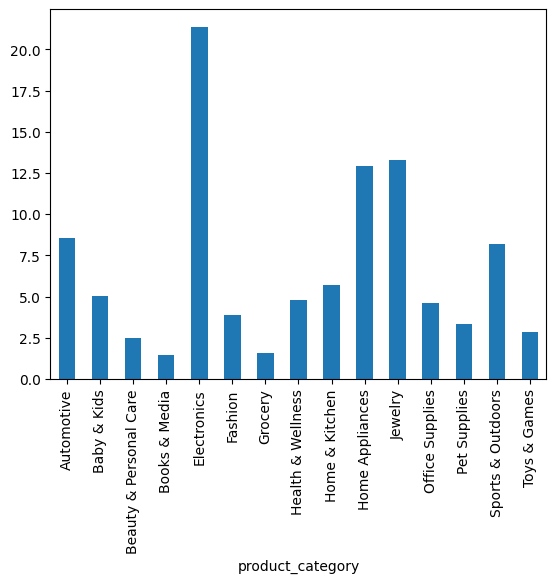

In [110]:
cat = item_df.groupby("product_category").agg(items=("order_id", "size"), revenue=("net_sales_ex_tax", "sum"))
cat["items_%"] = cat["items"] / cat["items"].sum() * 100
cat["revenue_%"] = cat["revenue"] / cat["revenue"].sum() * 100
print(cat.sort_values("revenue", ascending=False).round(1))
cat["revenue_%"].plot(kind="bar")

       unit_price   quantity  product_rating
count   397569.00  397569.00       397569.00
mean       245.19       2.12            3.68
std        251.04       1.20            0.70
min          6.31       1.00            2.50
25%         74.36       1.00            3.10
50%        164.97       2.00            3.70
75%        310.79       3.00            4.30
max       1482.95       5.00            4.90


<Axes: xlabel='unit_price', ylabel='Count'>

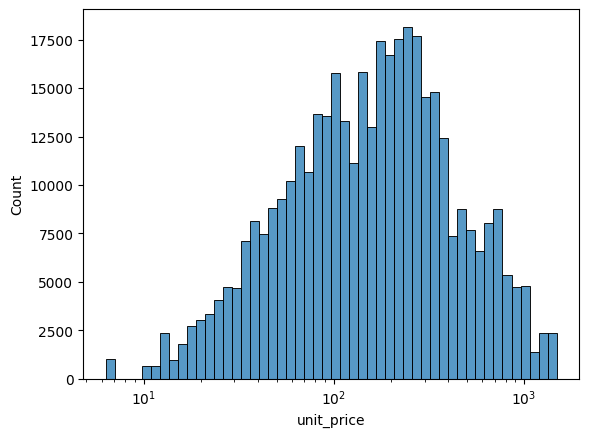

In [111]:
print(item_df[["unit_price", "quantity", "product_rating"]].describe().round(2))
sns.histplot(item_df["unit_price"], bins=50, log_scale=True)

### Observation: Distributions of unit price, quantity and product rating

**Subset:** all items (n = 397,569).

**1. `unit_price`:** ranges from 6.31 to 1,482.95. The mean (245.19) is above the median (164.97), so it is right-skewed. On a log scale it looks close to a bell shape with a peak around 200.

**2. `quantity`:** 1 to 5 units per item, median 2, mean 2.12. Most items have 1 to 3 units.

**3. `product_rating`:** 2.5 to 4.9, mean 3.68, median 3.7.

**4. What I cannot claim:** that price or rating affects profit. This is only the distribution.

**Open question:** is the small bump near 1,000 a group of premium products?

### 11.3 Profit by product

In [113]:
items_done = item_df[item_df["order_status"] == "Completed"].copy()



                        items  profit_per_item  margin_%  loss_%
product_category                                                
Electronics             21674            354.2      25.4     7.3
Automotive              22506            167.9      31.3     5.9
Jewelry                 19124            321.2      32.7     5.0
Home Appliances         21713            283.4      33.5     4.5
Sports & Outdoors       25180            178.1      38.7     3.3
Health & Wellness       24007            110.9      39.1     2.6
Home & Kitchen          19263            169.9      40.4     2.5
Fashion                 18945            124.3      42.7     2.0
Baby & Kids             21074            147.2      43.1     2.1
Pet Supplies            20523            102.1      44.4     1.5
Toys & Games            21760             83.8      44.9     1.1
Office Supplies         22314            133.0      45.3     1.4
Books & Media           24052             40.3      46.1     0.7
Beauty & Personal Care  2

<Axes: ylabel='product_category'>

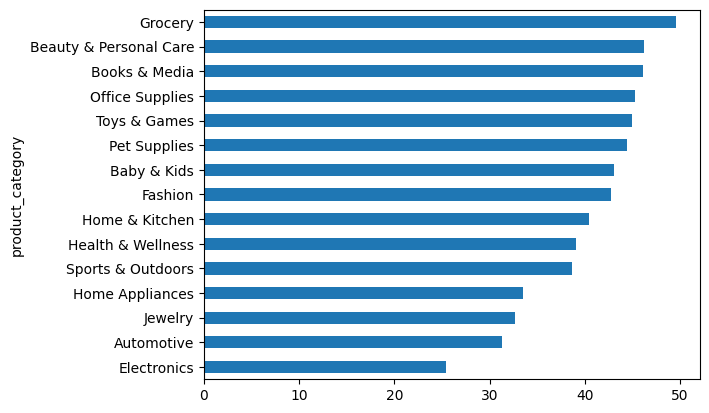

In [114]:
def profit_table(by):
    g = items_done.groupby(by, observed=True)
    return pd.DataFrame({
        "items": g.size(),
        "profit_per_item": g["profit_ex_tax"].mean(),
        "margin_%": g["profit_ex_tax"].sum() / g["net_sales_ex_tax"].sum() * 100,
        "loss_%": g["profit_ex_tax"].apply(lambda s: (s < 0).mean() * 100),
    }).round(1)

t = profit_table("product_category").sort_values("margin_%")
print(t)
t["margin_%"].plot(kind="barh")

In [115]:
t = profit_table("brand").sort_values("margin_%")
print(t.head(10)); print(t.tail(10))

             items  profit_per_item  margin_%  loss_%
brand                                                
Sony          1656            375.1      22.8     8.1
Xiaomi        1428            423.6      23.9     7.4
Asus          1939            446.3      24.4     7.0
Bvlgari       1086            245.8      24.5     7.2
Google        1663            343.0      25.9     7.0
Castrol       3942            139.8      26.1     7.2
Continental   1884            166.0      26.2     8.7
Microsoft     1371            280.0      26.3     8.8
LG            4528            265.0      26.4     7.0
Samsung       4461            304.3      26.5     6.9
               items  profit_per_item  margin_%  loss_%
brand                                                  
Kraft Heinz     1991             63.9      50.2     0.5
Coca-Cola       3060             49.9      50.2     0.4
Audible         1953             51.4      51.0     0.3
H&M             2180            146.1      51.2     1.1
Unilever        

In [116]:
items_done["price_band"] = pd.qcut(items_done["unit_price"], 5)
print(profit_table("price_band"))

                           items  profit_per_item  margin_%  loss_%
price_band                                                         
(6.308999999999999, 61.0]  65623             31.0      42.7     1.1
(61.0, 119.47]             65298             70.2      43.2     1.7
(119.47, 213.54]           65381            123.2      41.8     2.4
(213.54, 360.91]           65493            191.4      39.1     3.1
(360.91, 1482.95]          65233            352.7      30.6     5.3


/tmp/ipykernel_2308/2258129363.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = items_done.groupby(by)


### Observation: Profit by category, brand and price

**Subset:** Completed items; profit is `profit_ex_tax`.

**1. Category:** margin ranges from about 25% (Electronics) to about 50% (Grocery). The share of loss-making items is about 7% in Electronics and about 0.5% in Grocery. Expensive categories (Electronics, Automotive, Jewelry, Home Appliances) have the lowest margins. Electronics has the highest profit per item (about 354) but the lowest margin.

**2. Brand:** the lowest-margin brands (Sony, Xiaomi, Asus, Google, Microsoft, LG, Samsung) are mostly electronics brands, with margins of 23 to 26% and 6 to 9% loss-making items. The highest-margin brands (Graco, General Mills, Ravensburger, PaperMate) have margins of 50 to 55%.

**3. Price:** across 5 equal price bands, margin falls from 42.7% to 30.6% and the share of loss-making items rises from 1.1% to 5.3%.

**4. What I cannot claim:** that brand or price alone affects margin. Price and brand follow category, so the effect may be coming from category.

**Open question:** inside one category, do higher prices or discounts still lower the margin?

### 11.4 Discount and category

In [ ]:
# average discount (%) by category, Completed items
print(items_done.groupby('product_category')['discount_pct'].mean().round(1).sort_values())

In [ ]:
# Filter high discount items (more than 35% discount), Completed items
high_disc_df = items_done[items_done['discount_pct'] > 35]

loss_by_cat_high_disc = high_disc_df.groupby('product_category').agg(
    total_high_disc_items=('product_id', 'count'),
    loss_item_count=('profit_ex_tax', lambda x: (x < 0).sum()),
    loss_rate=('profit_ex_tax', lambda x: (x < 0).mean() * 100),
    total_loss_amount=('profit_ex_tax', lambda x: x[x < 0].sum())
).reset_index()

print("=== LOSS ANALYSIS AT >35% DISCOUNT ===")
print(loss_by_cat_high_disc.sort_values(by='total_loss_amount'))

In [ ]:
# Profit per Category

cat_profit = items_done.groupby('product_category').agg(
    total_net_sales = ('net_sales_ex_tax','sum'),
    total_profit = ('profit_ex_tax', 'sum'),
   loss_making_items=('profit_ex_tax', lambda x: (x < 0).mean() * 100)
).reset_index()

# Overall Profit Margin % = (Total Profit / Total Net Sales) * 100

# Overall Profit Margin % = (Total Profit / Total Net Sales) * 100

cat_profit['profit_margin_%'] = (cat_profit['total_profit']/ cat_profit['total_net_sales']) *100
print("\n=== CATEGORY PROFITABILITY & LOSS SHARE ===")
print(cat_profit[['product_category', 'profit_margin_%', 'loss_making_items']])

# Top 10 vs Bottom 10 Subcategories by Profit
subcat_p = items_done.groupby('product_subcategory')['profit_ex_tax'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
subcat_p.head(10).plot(kind='barh', ax=axes[0], color='green', title='Top 10 Profitable Subcategories')
subcat_p.tail(10).plot(kind='barh', ax=axes[1], color='red', title='Bottom 10 Loss-Making Subcategories')
axes[0].invert_yaxis()
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

### 11.5 Returns

=== RETURN RATE BY CATEGORY ===
          product_category  total_delivered  returned_items  return_rate
0               Automotive            24494            1988     8.116273
8           Home & Kitchen            20904            1641     7.850172
10                 Jewelry            20750            1626     7.836145
4              Electronics            23515            1841     7.829045
7        Health & Wellness            26044            2037     7.821379
13       Sports & Outdoors            27305            2125     7.782457
6                  Grocery            23565            1815     7.702101
3            Books & Media            26053            2001     7.680497
11         Office Supplies            24157            1843     7.629259
9          Home Appliances            23506            1793     7.627840
12            Pet Supplies            22201            1678     7.558218
2   Beauty & Personal Care            25024            1881     7.516784
14            Toys 

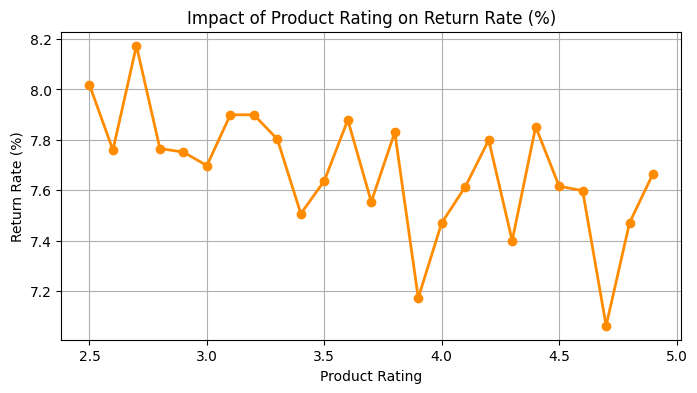

In [143]:
# Filter for items that successfully reached the customer (Completed + Returned)
delivered_df = item_df[item_df['order_status'].isin(['Completed', 'Returned'])].copy()

# Category-wise Return Rate calculation
returns_by_cat = delivered_df.groupby('product_category').agg(
    total_delivered=('returned', 'count'),
    returned_items=('returned', 'sum'),
    return_rate=('returned', lambda x: x.mean() * 100)
).reset_index().sort_values(by='return_rate', ascending=False)

print("=== RETURN RATE BY CATEGORY ===")
print(returns_by_cat)

# Rating vs Return Rate Plot
rating_returns = delivered_df.groupby('product_rating')['returned'].mean() * 100

plt.figure(figsize=(8, 4))
rating_returns.plot(kind='line', marker='o', color='darkorange', linewidth=2)
plt.title('Impact of Product Rating on Return Rate (%)', fontsize=12)
plt.xlabel('Product Rating')
plt.ylabel('Return Rate (%)')
plt.grid(True)
plt.show()

### Observation: Returns by category and rating

1. **Category Return Range:** Across all categories, the return rate remains fairly consistent between **7.3% and 8.1%**.
2. **Top Returned Categories:** `Automotive` (8.12%) and `Home & Kitchen` (7.85%) exhibit the highest return rates.
3. **Lowest Returned Categories:** `Baby & Kids` (7.33%) and `Fashion` (7.44%) show the lowest return rates.
4. **Rating vs. Return Impact:** Products with lower ratings (2.5 - 3.0) generally show higher return rates (~8.0%) compared to higher-rated products (4.5 - 5.0), though the relationship exhibits high variance across rating levels.

5. **Limitation:** `returned` at item level is the return flag of the whole order, not of the single item.

### 11.6 Basket size and co-purchases

=== BASKET SIZE VS PROFIT CORRELATION ===
                items_in_order  order_profit
items_in_order        1.000000      0.548469
order_profit          0.548469      1.000000


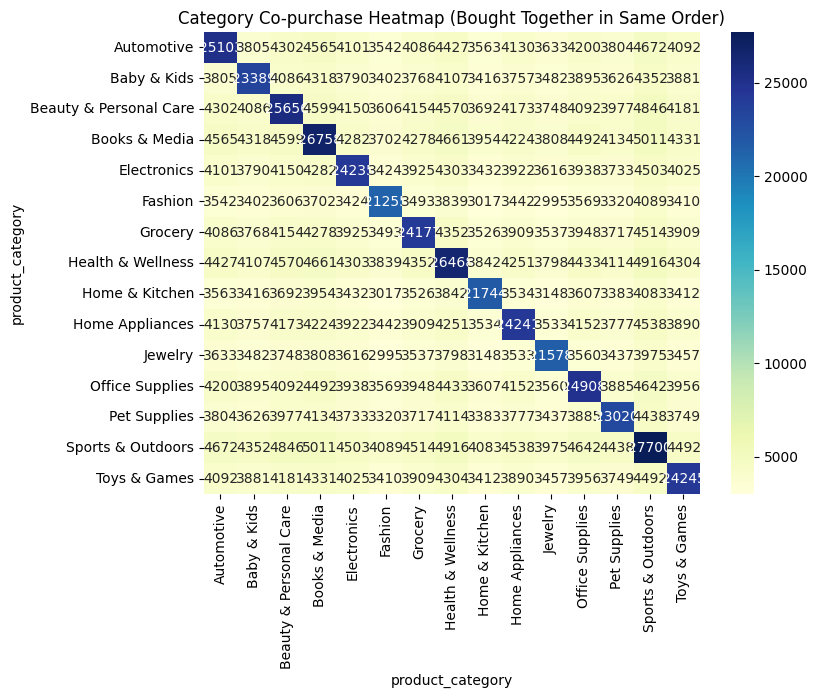

In [146]:
# 1. Items per order vs Profitability
basket = item_df.groupby('order_id').agg(
    items_in_order=('product_id', 'count'),
    order_profit=('profit_ex_tax', 'sum')
)

print("=== BASKET SIZE VS PROFIT CORRELATION ===")
print(basket.corr())

# 2. Co-purchase (Categories bought together)
# Creating a co-occurrence matrix for categories
order_cat_matrix = pd.crosstab(item_df['order_id'], item_df['product_category'])
order_cat_matrix = (order_cat_matrix > 0).astype(int) # Binary presence
co_matrix = order_cat_matrix.T.dot(order_cat_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(co_matrix, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Category Co-purchase Heatmap (Bought Together in Same Order)')
plt.show()

### 11.7 Seasonality

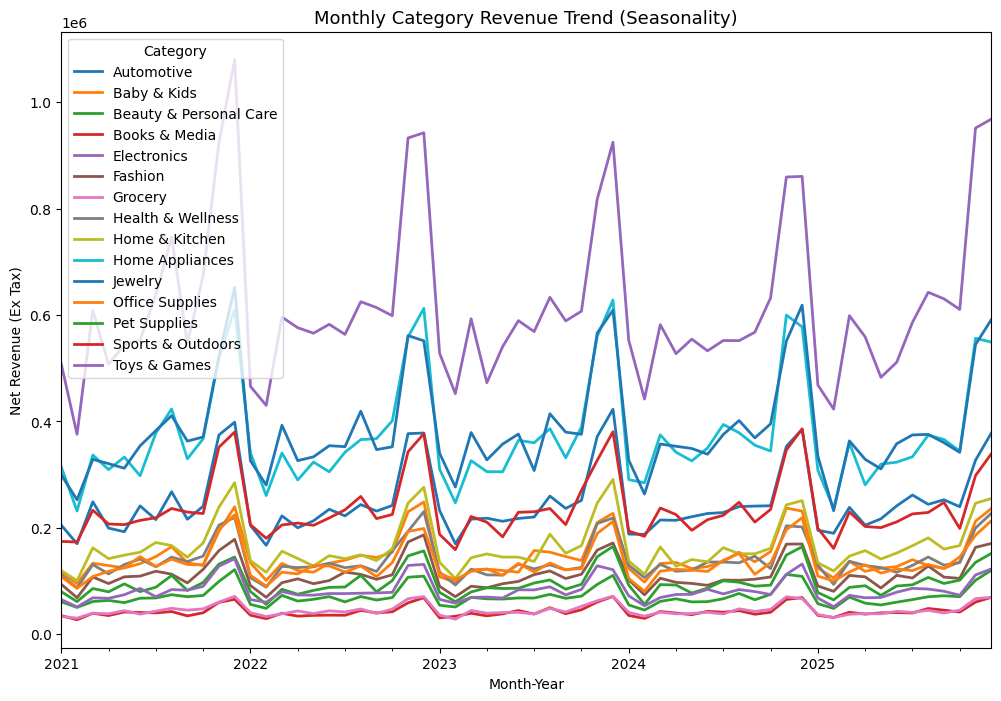

In [149]:
# Seasonality Trends
item_df['order_date'] = pd.to_datetime(item_df['order_date'])
item_df['year_month'] = item_df['order_date'].dt.to_period('M')

monthly_cat_sales = item_df.pivot_table(
    index='year_month',
    columns='product_category',
    values='net_sales_ex_tax',
    aggfunc='sum'
)

monthly_cat_sales.plot(figsize=(12, 8), linewidth=2)
plt.title('Monthly Category Revenue Trend (Seasonality)', fontsize=13)
plt.ylabel('Net Revenue (Ex Tax)')
plt.xlabel('Month-Year')
plt.legend(title='Category')
plt.show()

### 11.8 Conclusion: item-level analysis

**Data quality**
- 397,569 items, 26 columns, no nulls and no duplicate rows.
- `gross_sales` equals `unit_price × quantity`, `unit_price` is the same as the catalog price, and `product_cost` equals the catalog cost × quantity, so prices and costs are not changed after listing.
- `discount_percentage` is a fraction (mean 0.147, maximum 0.60) and matches `discount_amount / gross_sales`.
- `returned` at item level is the return flag of the whole order, not of the single item.

**Catalog**
- 15 categories, 117 subcategories, 144 brands and 10 suppliers.
- Every category has a similar number of items (5.8% to 7.7%), but revenue differs a lot because of price: Electronics 21.4%, Jewelry 13.3% and Home Appliances 12.9% of revenue; Books & Media and Grocery about 1.5% each.
- `unit_price` is right-skewed (mean 245, median 165); `quantity` is 1 to 5 (median 2); `product_rating` is 2.5 to 4.9 (mean 3.68).

**Main findings**
1. **Margin falls as price rises.** Margin is about 25% for Electronics, 31% for Automotive and 33% for Jewelry and Home Appliances, against about 50% for Grocery. The share of loss-making items is 7.3% for Electronics and 0.5% for Grocery. Across 5 equal price bands, margin falls from 42.7% to 30.6% and loss-making items rise from 1.1% to 5.3%.
2. **Electronics earns the most per item but the lowest margin.** Profit per item is 354, against 51 for Grocery.
3. **Brand follows category.** The lowest-margin brands (Sony, Xiaomi, Asus, Google, Microsoft, LG, Samsung) are electronics brands, with margins of 23 to 26% and 6 to 9% loss-making items. The highest-margin brands (Graco, General Mills, Ravensburger) are in low-price categories, with margins of 50 to 55%.
4. **Returns are similar everywhere.** The return rate is 7.3% to 8.1% in all categories. [add the rating and return result after printing the table]
5. **Discount by category.** [fill after re-running the discount cells: which categories get deeper discounts, and where do items above 35% discount lose money?]
6. **Basket size.** The number of items in an order and the order's total profit have a correlation of 0.55.

**Limitations**
- Descriptive only; averages, no significance tests.
- Price, brand and category move together, so the effect of one cannot be separated yet.
- Item-level totals differ from order-level totals, so these numbers are not compared directly with `order_df`.
- Item-level return is the order's return flag.

**For modeling**
- Features to try: `product_category`, `unit_price` (log), `discount_pct`, `quantity`, `product_rating`, `brand` (many values, needs careful encoding).
- Do not use `unit_price_catalog` together with `unit_price` (identical).

## 12. Next steps
- [x] Pending checks: `currency`, `customer_country`, `delivery_status`
- [x] Remove tax from profit (`profit_ex_tax`)
- [x] Discount bands and band × segment (H1, H2, H3)
- [x] Item-level analysis (`item_df`)
- [ ] Re-run the discount-by-category cells (11.4) and finish the item-level conclusion
- [ ] Re-run channel, age, gender and segment tables with `profit_ex_tax`
- [ ] Small checks: `delivery_days` for Returned orders, 511 "Early" orders with `days_vs_estimate = 0`, `payment_status` vs `order_status`, `region`
- [ ] Next notebooks: inferential statistics, feature engineering, modeling